<div style="background-color: #0f1056; color: white; padding: 10px; border-radius: 5px;">
    <h3>Import the libraries </h3>
</div>

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

<div style="background-color: #0f1056; color: white; padding: 10px; border-radius: 5px;">
    <h3>Variables for Plotting </h3>
</div>

In [2]:
# One consistent, calm plotting style for the whole lecture


BLUE, ORANGE, AQUA, GREY, INK, GREEN = "#2a78d6", "#eb6834", "#1baf7a", "#898781", "#0b0b0b", "#294D3D"


plt.rcParams.update({
    "figure.figsize": (9, 4.5), "figure.dpi": 110,
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": INK, "axes.titleweight": "bold",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 11,
})
rng = np.random.default_rng(42)     # fixed seed, so every student gets the same "random" results

In [3]:
tips = sns.load_dataset("tips")

tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


<div style="background-color: #0f1056; color: white; padding: 10px; border-radius: 5px;">
    <h3> What is Probability </h3>
</div>

It's Saturday night and our waiter is getting ready for the shift. A friend asks, "What's the chance your next table is a Saturday table?" The waiter laughs: "Tonight? It's certain." Then the friend asks something harder: "Across **all** your shifts, if I picked one of your tables at random, what's the chance it was from a Saturday?"

The waiter has a notebook with 244 tables in it, so they can answer by **counting**.

### The idea
$$P(\text{event}) = \frac{\text{number of ways the event can happen}}{\text{total number of possible outcomes}}$$

- Probabilities are always between **0** (impossible) and **1** (certain).
- 0.25 = 25% = "1 in 4" = "about a quarter of the time". These all mean the same thing.
- **Complement rule:** P(not A) = 1 − P(A). If there's a 30% chance of rain, there's a 70% chance of no rain.

### Two rules for combining events

**Addition rule (OR).** What's the chance of A *or* B?
$$P(A \text{ or } B) = P(A) + P(B) - P(A \text{ and } B)$$
We subtract the overlap because otherwise we'd count it twice. Picture a Venn diagram: two circles that overlap. If the events *can't* happen together (**mutually exclusive**, like "Saturday" and "Sunday"), the overlap is 0 and you just add.

**Multiplication rule (AND).** What's the chance of A *and* B?
$$P(A \text{ and } B) = P(A) \times P(B) \quad \text{(only when A and B are independent)}$$


In [4]:
# Probability by counting

n = len(tips)
p_sat     = (tips["day"] == "Sat").sum() / n
p_sun     = (tips["day"] == "Sun").sum() / n
p_smoker  = (tips["smoker"] == "Yes").sum() / n
p_sat_and_smoker = ((tips["day"] == "Sat") & (tips["smoker"] == "Yes")).sum() / n

In [5]:
# Probability that a day at random is Saturday

print(f"P(Saturday)            = {p_sat:.3f}")

P(Saturday)            = 0.357


In [6]:
# Probability that a day at random is NOT Saturday

print(f"P(NOT Saturday)        = {1 - p_sat:.3f}   <- complement rule")

P(NOT Saturday)        = 0.643   <- complement rule


##### Addition rule, no overlap (mutually exclusive)

In [7]:
# Probability that a given day is either saturday or sunday

print(f"P(Sat OR Sun)          = {p_sat:.3f} + {p_sun:.3f} = {p_sat + p_sun:.3f}   (a table can't be both)")


P(Sat OR Sun)          = 0.357 + 0.311 = 0.668   (a table can't be both)


##### Addition rule, with overlap

In [8]:
# Probability that for a given random selection; the day is saturday or the person is a smoker

p_sat_or_smoker = p_sat + p_smoker - p_sat_and_smoker
check = ((tips["day"] == "Sat") | (tips["smoker"] == "Yes")).mean()
print(f"P(Sat OR smoker)       = {p_sat:.3f} + {p_smoker:.3f} - {p_sat_and_smoker:.3f} = {p_sat_or_smoker:.3f}")
print(f"   ...check by direct counting: {check:.3f}  ✓")

P(Sat OR smoker)       = 0.357 + 0.381 - 0.172 = 0.566
   ...check by direct counting: 0.566  ✓


In [9]:
# Multiplication rule (independent events): two coin flips

print(f"P(two heads in a row)  = 0.5 x 0.5 = {0.5*0.5}")

P(two heads in a row)  = 0.5 x 0.5 = 0.25


In [10]:
# Three dice

print(f"P(three sixes in a row)= (1/6)^3   = {(1/6)**3:.4f}  (about 1 in 216)")

P(three sixes in a row)= (1/6)^3   = 0.0046  (about 1 in 216)


**Things to note:**

- Just adding P(Sat) + P(smoker) would give **0.738**, but the true answer is **0.566**. The difference is the Saturday-smokers, who were counted twice.


**Application:** every metric of the form "what fraction of customers do X *or* Y" or "X *and* Y" is one of these two rules. A wrong answer to an "or" question usually means someone counted the overlap twice.

<div style="background-color: #0f1056; color: white; padding: 10px; border-radius: 5px;">
    <h3> Frequency tables and simulations </h3>
</div>

### The story
The waiter's manager asks, "Which days should we staff up, and should the smoking section be bigger?" The waiter doesn't need a formula for this. They need a **frequency table**: a count of how often each thing happened.

Later, the manager asks something the notebook can't answer: "If we got 1,000 tables, how many smokers would there be?" There's no data for 1,000 tables. So we **simulate**: we let the computer play out the situation thousands of times, the way a flight simulator lets a pilot practise a crash landing without crashing a plane.

The idea is to generate random outcomes on a computer many times and count them.The more times you repeat an experiment, the closer the observed frequency gets to the true probability. Flip a coin 10 times and you might get 7 heads. Flip it 10,000 times and you'll get very close to 50%.


1. **Frequency table:** count each outcome. Divide by the total to get the **relative frequency**, which is our *estimate* of the probability.
2. **Two-way table (contingency table):** count combinations of two things, e.g. day × smoker. You'll use these constantly in data analysis.


### Relevance and significance
- Most probabilities in business aren't calculated from formulas. They're **counted from data**: click rates, return rates, fraud rates.
- Simulation (often called the *Monte Carlo method*) is used for pricing financial products, testing supply chains, planning hospital beds and forecasting elections.

### Why a data scientist needs this
A frequency table is usually the first thing you build with a new dataset (`value_counts()` and `pd.crosstab()` in pandas). Simulation lets you answer "what if?" questions without a formula, and lets you **check** any formula you do use.

<h3 style="color: maroon;">One way frequency table</h3>

A frequency table counts how many times each possible value appears in your data.

The waiter goes through the 244 tables in the notebook and counts how many came on each day.


### The table uses two terms:

1. Frequency is the raw count, such as 87 Saturday tables.
2. Probability is that count divided by the total, such as 0.357. It's the proportion of the data that has that value, and all the relative frequencies add up to 1.

### Purpose of one way frequency tables:

- Answers the question on what is the distribution of data in a column, count wise and as a % of whole
- Most real-world probabilities come from counting, not formulas.
- It's the first step with any new dataset
- Founding stone for building on business decisions

Let us get back to the original question - Which days should we staff up, and should the smoking section be bigger?

In [11]:
# 1) One-way frequency table: which day do tables come in?

freq = tips["day"].value_counts().reindex(["Thur", "Fri", "Sat", "Sun"])
table = pd.DataFrame({"count": freq, "probability": (freq / freq.sum()).round(3)})
print(table, "\n")

      count  probability
day                     
Thur     62        0.254
Fri      19        0.078
Sat      87        0.357
Sun      76        0.311 



<h3 style="color: maroon;">Two way frequency table</h3>


### 

A two-way table counts combinations of two variables at once. One variable goes in the rows, the other in the columns, and each cell counts the rows that have both values.


### Purpose of one way frequency tables:
    
A two way frequency table shows relationships between variables, which a one-way table can't. 
On average, 38% of tables are smokers. 
On Fridays the figure is 79%. 

That gap tells you day and smoking are dependent. Two one-way tables, one for day and one for smoker, would never have shown you that.

In [12]:
# 2) Two-way frequency table: day x smoker

two_way = pd.crosstab(tips["day"], tips["smoker"], margins=True, margins_name="Total")
two_way

smoker,Yes,No,Total
day,,,
Thur,17,45,62
Fri,15,4,19
Sat,42,45,87
Sun,19,57,76
Total,93,151,244


**Reading the two-way table:** 

- 42 of the 87 Saturday tables were smokers. 
- Friday is odd: **15 of 19** Friday tables were smokers. 


<div style="background-color: #0f1056; color: white; padding: 10px; border-radius: 5px;">
    <h3> When outcome of one event affect each other </h3>
</div>

### The story
Two customers walk into the café. One is a man and one is a woman. The waiter wonders 

-- whether one is more likely than the other to be a smoker. And does knowing it's **Friday** tell the waiter anything about whether the table smokes?

### Independent vs dependent
- **Independent:** knowing A tells you *nothing* about B. Example: two coin flips. The coin doesn't remember the last flip.
- **Dependent:** knowing A *changes* the chance of B. Example: drawing two cards without putting the first back. After you've drawn an ace, there are fewer aces left.

### Conditional probability: "given that…"
$$P(A \mid B) = \frac{P(A \text{ and } B)}{P(B)}$$
Read the bar "|" as **"given that"**. The trick: **shrink your world down to just the B cases, then ask how many of them are A.**

In the two-way table this means: **look at only one row, and divide by that row's total.**

**Test for independence:** A and B are independent if `P(A | B) = P(A)`. Learning B didn't change anything.

The multiplication rule for dependent events then becomes: $P(A \text{ and } B) = P(B) \times P(A \mid B)$.

In [13]:
# overall

p_smoker = (tips["smoker"] == "Yes").mean()

print(f"P(smoker)            = {p_smoker:.3f}")

P(smoker)            = 0.381


<h3 style="color: maroon;">1. Is smoking independent of Gender?</h3>

In [14]:
# Smoker, given the person is a male

p_smoker_given_male   = (tips.loc[tips["sex"] == "Male",   "smoker"] == "Yes").mean()
print(f"P(smoker | Male)     = {p_smoker_given_male:.3f}")

P(smoker | Male)     = 0.382


In [15]:
# Smoker, given the person is a female

p_smoker_given_female = (tips.loc[tips["sex"] == "Female", "smoker"] == "Yes").mean()
print(f"P(smoker | Female)   = {p_smoker_given_female:.3f}")

P(smoker | Female)   = 0.379


<h4 style="color: maroon;"> Conclusion </h4>

In [16]:
print("--- Gender vs smoker ---")
print("-> almost identical, so sex and smoking look INDEPENDENT here\n")

--- Gender vs smoker ---
-> almost identical, so sex and smoking look INDEPENDENT here



<div style="background-color: #4C294D; color: white; padding: 10px; border-radius: 5px;">
    <h3> Is smoking independent of day? (Tuesday)  </h3>
</div>

In [17]:
# Is smoking independent of day?

print("--- Day vs smoker ---")
p_by_day = tips.groupby("day", observed=True)["smoker"].apply(lambda s: (s == "Yes").mean())
for day, p in p_by_day.items():
    print(f"P(smoker | {day:<4}) = {p:.3f}")
print("-> Friday is about 0.79 vs 0.38 overall, so day and smoking are DEPENDENT\n")



--- Day vs smoker ---
P(smoker | Thur) = 0.274
P(smoker | Fri ) = 0.789
P(smoker | Sat ) = 0.483
P(smoker | Sun ) = 0.250
-> Friday is about 0.79 vs 0.38 overall, so day and smoking are DEPENDENT



<div style="background-color: #4C294D; color: white; padding: 10px; border-radius: 5px;">
    <h3> Visualize - smoker | day (Tuesday)  </h3>
</div>



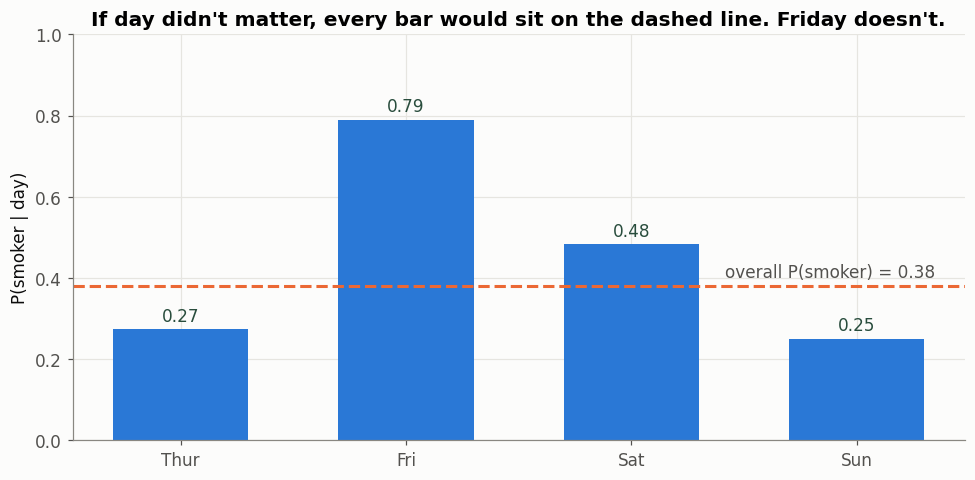

In [18]:
fig, ax = plt.subplots()
days = p_by_day.index.astype(str)
ax.bar(days, p_by_day.values, color=BLUE, width=0.6)
ax.axhline(p_smoker, color=ORANGE, lw=2, ls="--")
ax.text(3.35, p_smoker + 0.02, f"overall P(smoker) = {p_smoker:.2f}", ha="right", color="#52514e")


for i, v in enumerate(p_by_day.values):
    ax.text(i, v + 0.02, f"{v:.2f}", ha="center", color=GREEN)

    
ax.set_ylim(0, 1); ax.set_ylabel("P(smoker | day)")
ax.set_title("If day didn't matter, every bar would sit on the dashed line. Friday doesn't.")
plt.tight_layout(); plt.show()

<div style="background-color: #0f1056; color: white; padding: 10px; border-radius: 5px;">
    <h3> Bayes Theorem </h3>
</div>

Knowing P(smoker | Friday) is **not** the same as knowing P(Friday | smoker). People mix these up all the time, and it causes real mistakes.

$$P(A \mid B) = \frac{P(B \mid A)\, P(A)}{P(B)}$$

In words: **start with what you believed before (the *prior*, P(A)). Then update it using how likely the evidence is if A were true.**


**Applications** 

1.	Medical testing: "I tested positive. How likely is it that I actually have the disease?" 
2.	Spam filtering: "Given the words in this email ('free', 'winner', 'urgent'), how likely is it to be spam?" 
3.	Fraud detection: "Given this transaction's amount, location and time, how likely is it to be fraud?" 
4.	A/B testing: "Given the conversions so far, how likely is it that version B beats version A?" 
5.	Recommendations and search: "Given what this user clicked, how likely are they to want this item?" 
6.	Navigation and robotics: "Given this noisy GPS or sensor reading, where am I really?" 
7.	Weather forecasting: "Given today's pressure, humidity and radar readings, what's the chance of rain?" 


<div style="background-color: #4C294D; color: white; padding: 10px; border-radius: 5px;">
    <h3> Application of Bayes Theorem </h3>
</div>

##### The Medical Test Problem (Tuesday)

## The Problem

A disease affects **1%** of the population. There is a test for it:

- If you **have** the disease, the test is positive **90%** of the time.
- If you **don't** have it, the test is still positive **5%** of the time (a false positive).

You test positive. **What is the chance you actually have the disease?**





### Applying Bayes' Theorem

$$
P(A \mid B) = \frac{P(B \mid A) \cdot P(A)}{P(B)}
$$

Here, $A$ = "has the disease" ($D$) and $B$ = "tests positive" ($+$).

| Term | Meaning | Value |
|---|---|---|
| $P(D)$ | **Prior**: chance of having the disease before testing | 0.01 |
| $P(+ \mid D)$ | **Likelihood**: chance of a positive test if you have it | 0.90 |
| $P(+ \mid \neg D)$ | **False-positive rate**: chance of a positive test if you don't have it | 0.05 |
| $P(D \mid +)$ | **Posterior**: what we want to find | ? |



### Step-by-Step Solution

### Step 1: Find the total chance of testing positive, $P(+)$

A positive result can come from a sick person **or** a healthy person (law of total probability):

$$
P(+) = P(+ \mid D)\,P(D) + P(+ \mid \neg D)\,P(\neg D)
$$



$$
Chance of testing positive = (chance a sick person tests positive × chance of being sick) + (chance a healthy person tests positive × chance of being healthy)
$$



$$
P(+) = (0.90 \times 0.01) + (0.05 \times 0.99) = 0.009 + 0.0495 = 0.0585
$$

### Step 2: Apply Bayes' theorem

$$
P(D \mid +) = \frac{P(+ \mid D)\,P(D)}{P(+)} = \frac{0.90 \times 0.01}{0.0585} = \frac{0.009}{0.0585} \approx 0.154
$$

> **Answer: $P(D \mid +) \approx 15.4\%$**



### Seeing It with 10,000 People

Counting people instead of using probabilities makes the result easier to see:

```
                     10,000 people
                    /             \
           100 sick                9,900 healthy
           /      \                 /         \
    90 test +   10 test –    495 test +    9,405 test –
```

| | Test + | Test – | Total |
|---|---|---|---|
| **Sick** | 90 | 10 | 100 |
| **Healthy** | 495 | 9,405 | 9,900 |
| **Total** | **585** | 9,415 | 10,000 |

- **585** people test positive in total (90 + 495).
- Only **90** of them are actually sick.
- $90 / 585 \approx$ **15.4%**



## Why the Answer Is So Low

- **The disease is rare.** So many people are healthy that even a 5% false-positive rate produces far more false alarms (495) than true cases (90).
- **The test result is evidence, not the final answer.** Bayes combines what you knew before (the 1% prior) with new evidence (a positive test) to get an updated belief (15.4%).



## The key idea: yesterday's answer becomes today's starting point

Before the first test, all we knew was that 1% of people have the disease, so your starting chance was 1%.

After one positive test, we worked out your chance had risen to 15.4%.

Now you take a second test. You're no longer a random person from the population. You're someone who already tested positive once, so your starting chance for this round is 15.4%, not 1%.

That's the core of Bayes' theorem: each new piece of evidence updates what you believed before.



- **A second test helps a lot.** If you test positive again, use 15.4% as the new prior and repeat the calculation:

$$
P(D \mid ++) = \frac{0.90 \times 0.154}{(0.90 \times 0.154) + (0.05 \times 0.846)} = \frac{0.1385}{0.1808} \approx 0.77
$$

The chance rises to about **77%**.



### Where Bayes' Theorem Is Used

- **Spam filters:** updating the probability that an email is spam based on the words it contains.
- **Fraud detection:** flagging transactions based on how unusual they are given a customer's history.
- **Medical diagnosis:** interpreting test results in light of how common a disease is.
- **Machine learning:** Naive Bayes classifiers and Bayesian inference for updating model beliefs with data.

<div style="background-color: #0f1056; color: white; padding: 10px; border-radius: 5px;">
    <h3> Random variables and probability distributions </h3>
</div>


The restaurant manager has one worry at the start of every shift: **"How big will the next group be?"** The answer is a number, but we don't know which number until the group walks in.

### The idea
A **random variable** is **a number whose value depends on chance.** We give it a capital letter:

- X = the size of the next party
- Y = the bill for the next table
- Z = the number of customers who buy milk at FreshMart tomorrow

It isn't "random" in the sense of chaotic. It's a number we can't know in advance, but we can describe **how likely each value is.**

A **probability distribution** is that description: **the pattern of all possible outcomes and how often each happens.** Think of it as the random variable's personality profile. It tells you:

- what values are possible,
- which values are common and which are rare,
- the typical value (the **expected value**, or long-run average): $E[X] = \sum x \cdot P(X = x)$.

### Relevance and significance
Individual customers are unpredictable, but the *distribution* is stable. 

### Why a data scientist needs this
- **Every column in a dataset is a random variable.** Before you model it, you look at its distribution.
- Predictions are more useful with a range. "We'll sell 500 ± 60 litres" is more useful than "we'll sell 500".
- Many machine-learning models *assume* a distribution (for example, linear regression assumes the errors are normal). If you don't know what the data's distribution looks like, you can't tell whether the model is appropriate.

### Real-world example
A restaurant has to decide how to lay out its tables: how many 2-seaters and how many 4-seaters? You can't know the next party size, but you can know its distribution.

> **Problem.** Let X = the size of a party at the café.
> 1. Find the probability distribution of X from the data.
> 2. What's P(X ≥ 4), the chance a group needs a big table?
> 3. What's E[X], the average party size? If the café expects 60 parties on a Saturday, roughly how many **customers** (covers) should the kitchen prepare for?

In [19]:
# 1) The probability distribution of X = party size

dist_X = tips["size"].value_counts(normalize=True).sort_index()
print("x   P(X = x)")


for x, p in dist_X.items():
    print(f"{x}   {p:.3f}")
print(f"sum = {dist_X.sum():.3f}   <- a distribution always adds up to 1")



x   P(X = x)
1   0.016
2   0.639
3   0.156
4   0.152
5   0.020
6   0.016
sum = 1.000   <- a distribution always adds up to 1


In [20]:
# 2) P(X >= 4) - What are the chances of a big table

p_big = dist_X[dist_X.index >= 4].sum()

print(f"\nP(X >= 4) = {p_big:.3f}  -> about 1 group in {1/p_big:.0f} needs a big table")



P(X >= 4) = 0.189  -> about 1 group in 5 needs a big table


In [21]:
# 3) Expected value - what is the typical party size

E_X = float(np.sum(dist_X.index.to_numpy() * dist_X.to_numpy()))
print(f"E[X] = sum of x * P(x) = {E_X:.2f} people per party")
print(f"60 parties x {E_X:.2f} ≈ {60*E_X:.0f} covers to prepare for")


E[X] = sum of x * P(x) = 2.57 people per party
60 parties x 2.57 ≈ 154 covers to prepare for


<div style="background-color: #4C294D; color: white; padding: 10px; border-radius: 5px;">
    <h3> visualize the expected party size, with large size and regular size  </h3>
</div>

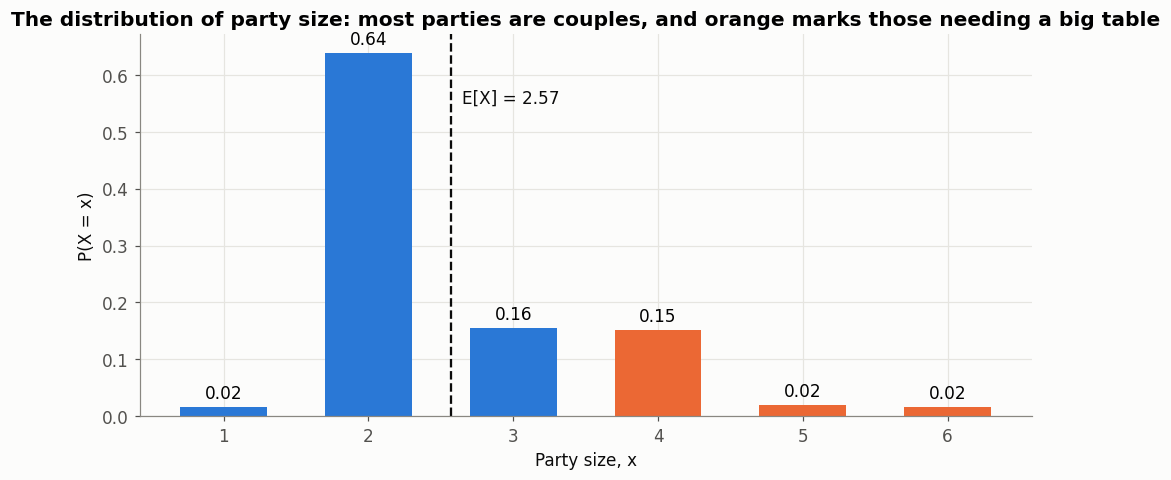

In [22]:
fig, ax = plt.subplots()
colors = [ORANGE if x >= 4 else BLUE for x in dist_X.index]
ax.bar(dist_X.index, dist_X.values, color=colors, width=0.6)
for x, p in dist_X.items():
    ax.text(x, p + 0.015, f"{p:.2f}", ha="center")
ax.axvline(E_X, color=INK, ls="--", lw=1.5)
ax.text(E_X + 0.08, 0.55, f"E[X] = {E_X:.2f}", color=INK)
ax.set_xlabel("Party size, x"); ax.set_ylabel("P(X = x)")
ax.set_title("The distribution of party size: most parties are couples, and orange marks those needing a big table")
plt.tight_layout(); plt.show()

**Things to point out:** the expected value (2.57) isn't a party size anyone can actually have, since nobody arrives as 2.57 people. It's a **long-run average**, and that's exactly what the kitchen needs for planning.

<div style="background-color: #0f1056; color: white; padding: 10px; border-radius: 5px;">
    <h3> Discrete vs continuous </h3>
</div>

# Describing Data with Distributions: PMF, PDF, CDF & ECDF
### Using the `tips` dataset from Seaborn

**Where this fits:** You already know what **continuous** and **discrete** variables are. This notebook shows how to **draw** how their values are spread, and how to **describe** what you see.

**By the end you will be able to:**
1. Tell discrete and continuous variables apart, and know how each is represented
2. Choose the right plot: **PMF, PDF, CDF or ECDF**
3. Draw each one in Python and **describe it in plain English**

| Section | Plot | Variable used |
|:---:|:---|:---|
| 1 | Discrete vs Continuous | all columns |
| 2 | PMF vs PDF vs CDF vs ECDF | overview |
| 3 | **PMF** | `size` (discrete) |
| 4 | **PDF** | `total_bill` (continuous) |
| 5 | **CDF** | `tip` (continuous) |
| 6 | **ECDF** | `size` (discrete) |


## 1. Discrete vs Continuous Variables

| | **Discrete variable** | **Continuous variable** |
|---|---|---|
| **(a) What it is** | A value you **count**. It can only take separate, fixed values (usually whole numbers), with gaps in between. | A value you **measure**. It can take **any** value in a range, including decimals. |
| **Quick test** | *"Can I have 2.5 of it?"* **No** | *"Can I have 2.5 of it?"* **Yes** |
| **(b) How it's represented** | **Bar chart / PMF**: a separate bar for each value, with gaps. **ECDF**: a staircase of steps. | **Histogram** (touching bars over ranges), **PDF**: a smooth curve. **CDF**: a smooth rising curve. |
| **Probability question** | *"What's the chance of **exactly** 2?"* makes sense. | *"What's the chance of **exactly** \$17.2300…?"* is essentially **0**, so we ask about **ranges** (e.g. \$10–\$20). |
| **(c) Examples: everyday** | Number of students in a class, goals in a match, cars in a car park, dice roll | Height, weight, temperature, time to finish a race |
| **(c) Examples: tips dataset** | `size` (people at the table: 1, 2, 3…6) | `total_bill`, `tip` (any dollar amount) |

> **Note:** `sex`, `smoker`, `day` and `time` are **categorical** (labels, not numbers), so they are neither discrete nor continuous in this sense.

Let's classify every column in the dataset:

In [23]:
summary = pd.DataFrame({
    "Column":        ["total_bill", "tip", "size", "sex", "smoker", "day", "time"],
    "Type":          ["Continuous", "Continuous", "Discrete", "Categorical", "Categorical", "Categorical", "Categorical"],
    "Why":           ["Money: any amount, e.g. 16.99", "Money: any amount, e.g. 1.01",
                      "People: counted, 1 to 6", "Label", "Label", "Label", "Label"],
    "Unique values": [tips[c].nunique() for c in ["total_bill", "tip", "size", "sex", "smoker", "day", "time"]],
})
summary

,Column,Type,Why,Unique values
0,total_bill,Continuous,"Money: any amount, e.g. 16.99",229
1,tip,Continuous,"Money: any amount, e.g. 1.01",123
2,size,Discrete,"People: counted, 1 to 6",6
3,sex,Categorical,Label,2
4,smoker,Categorical,Label,2
5,day,Categorical,Label,4
6,time,Categorical,Label,2



## 2. PMF vs PDF vs CDF vs ECDF

| | **PMF**<br>Probability *Mass* Function | **PDF**<br>Probability *Density* Function | **CDF**<br>Cumulative Distribution Function | **ECDF**<br>*Empirical* CDF |
|---|---|---|---|---|
| **Used for** | Discrete | Continuous | Both (usually continuous) | Both (great for discrete) |
| **Question it answers** | *"Chance of **exactly** x?"* | *"Where are the values **concentrated**?"* | *"Chance of **x or less**?"* | *"What **fraction of my data** is x or less?"* |
| **What the height means** | A probability | **Not** a probability. Only the **area** under the curve is. | A probability (0 to 1) | A proportion (0 to 1) |
| **Looks like** | Separate bars / lollipops | Smooth hill-shaped curve | Smooth S-shaped curve rising to 1 | Staircase rising to 1 |
| **Adds up to** | All bars add to **1** | Total **area** = 1 | Ends at **1** | Ends at **1** |
| **Built from** | Counts ÷ total | A smoothed estimate (KDE) | Running total of the PDF | Directly from the data, no smoothing |
| **Seaborn** | `histplot(stat="probability", discrete=True)` | `kdeplot()` | `kdeplot(cumulative=True)` | `ecdfplot()` |
| **Tips example** | `size` | `total_bill` | `tip` | `size` |

**How they connect:**
- **PMF / PDF** show *how much is at each value* (the **shape**).
- **CDF / ECDF** show *how much has piled up so far* (the **running total**).
- Add up PMF bars left to right and you get the ECDF steps. Add up the area under the PDF and you get the CDF.

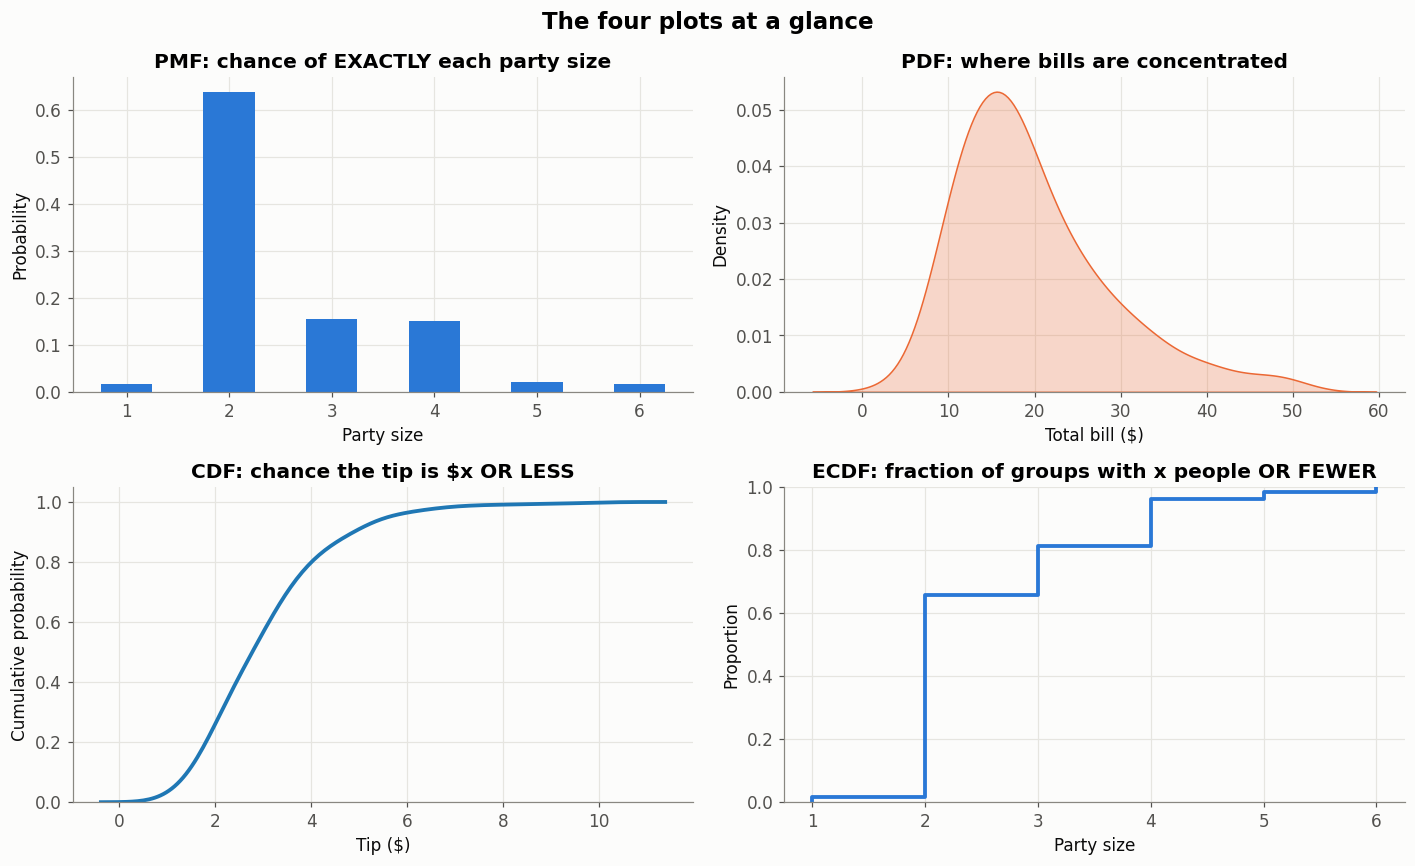

In [24]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8))

# PMF
pmf = tips["size"].value_counts(normalize=True).sort_index()
ax[0, 0].bar(pmf.index, pmf.values, color=BLUE, width=0.5)
ax[0, 0].set(title="PMF: chance of EXACTLY each party size", xlabel="Party size", ylabel="Probability")

# PDF
sns.kdeplot(data=tips, x="total_bill", fill=True, color=ORANGE, ax=ax[0, 1])
ax[0, 1].set(title="PDF: where bills are concentrated", xlabel="Total bill ($)")

# CDF
sns.kdeplot(data=tips, x="tip", cumulative=True,  lw=2.5, ax=ax[1, 0])
ax[1, 0].set(title="CDF: chance the tip is $x OR LESS", xlabel="Tip ($)", ylabel="Cumulative probability")

# ECDF
sns.ecdfplot(data=tips, x="size", color=BLUE, lw=2.5, ax=ax[1, 1])
ax[1, 1].set(title="ECDF: fraction of groups with x people OR FEWER", xlabel="Party size")

for a in ax.flat:
    a.title.set_fontweight("bold")
plt.suptitle("The four plots at a glance", fontsize=15, fontweight="bold")
plt.tight_layout(); plt.show()

### Step 3: Illustrated version, showing what the PDF captures

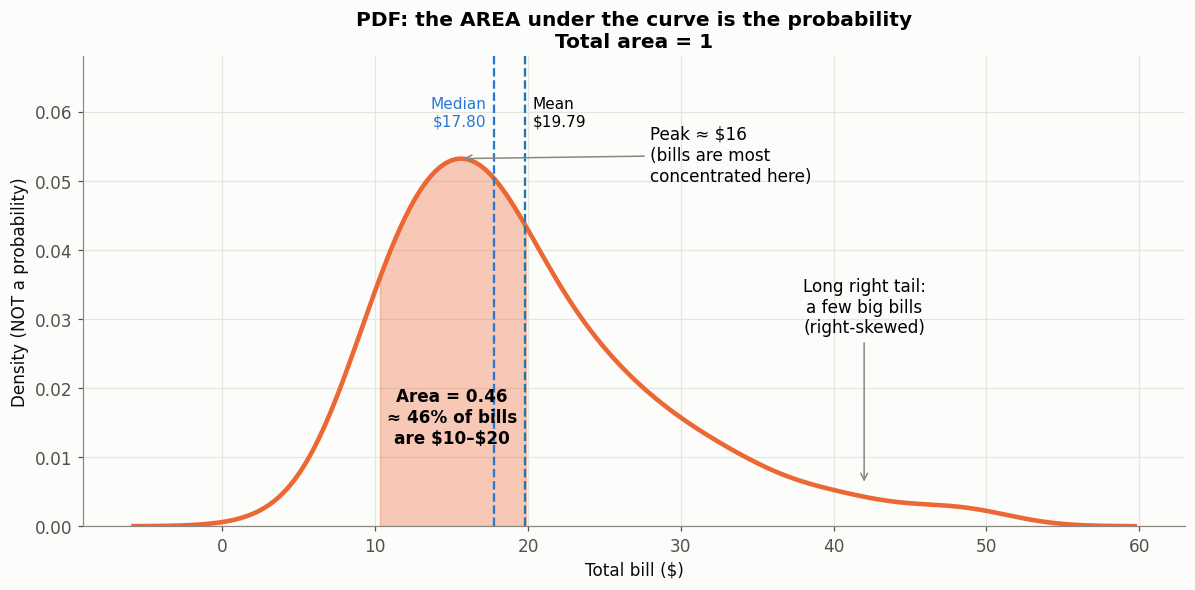

Smooth-curve (PDF) estimate: 46%
Counting the raw data:       53% of bills are between $10 and $20


In [25]:
fig, ax = plt.subplots(figsize=(11, 5.5))
sns.kdeplot(data=tips, x="total_bill", color=ORANGE, lw=3, ax=ax)

# Get the curve's points so we can shade and annotate it
x, y = ax.lines[0].get_data()

# 1) Shade the AREA between $10 and $20: this area is a probability
mask = (x >= 10) & (x <= 20)
xm, ym = x[mask], y[mask]
area = np.sum((ym[1:] + ym[:-1]) / 2 * np.diff(xm))   # trapezoid rule = area under curve
ax.fill_between(x[mask], y[mask], color=ORANGE, alpha=0.35)
ax.text(15, 0.012, f"Area = {area:.2f}\n≈ {area:.0%} of bills\nare \\$10–\\$20",
        ha="center", fontsize=11, fontweight="bold")

# 2) Mark the peak (most concentrated value)
peak_x = x[np.argmax(y)]
ax.annotate(f"Peak ≈ ${peak_x:.0f}\n(bills are most\nconcentrated here)",
            xy=(peak_x, y.max()), xytext=(28, 0.050), fontsize=11,
            arrowprops=dict(arrowstyle="->", color=GREY))

# 3) Mean vs median
mean, median = tips["total_bill"].mean(), tips["total_bill"].median()
ax.axvline(median, color=BLUE, ls="--", lw=1.5)
ax.axvline(mean, ls="--", lw=1.5)
ax.text(median - 0.5, 0.058, f"Median\n${median:.2f}", color=BLUE, ha="right", fontsize=10)
ax.text(mean + 0.5, 0.058, f"Mean\n${mean:.2f}", ha="left", fontsize=10)

# 4) The long right tail
ax.annotate("Long right tail:\na few big bills\n(right-skewed)",
            xy=(42, 0.006), xytext=(42, 0.028), ha="center", fontsize=11,
            arrowprops=dict(arrowstyle="->", color=GREY))

ax.set(xlabel="Total bill ($)", ylabel="Density (NOT a probability)", ylim=(0, 0.068))
ax.set_title("PDF: the AREA under the curve is the probability\nTotal area = 1", fontweight="bold")
plt.tight_layout(); plt.show()

print(f"Smooth-curve (PDF) estimate: {area:.0%}")
print(f"Counting the raw data:       {((tips.total_bill >= 10) & (tips.total_bill <= 20)).mean():.0%} of bills are between $10 and $20")

### What the PDF captures
- **Shape:** where values bunch up (the peak) and where they thin out (the tails).
- **Area = probability.** The shaded area between \$10 and \$20 is the chance a bill falls in that range.
- **Height is NOT a probability.** A density of 0.05 doesn't mean "5%". Only **areas** are probabilities.
- **Total area under the curve = 1** (100% of bills).
- **It's a smoothed estimate.** The curve's area (≈46%) is close to, but not exactly, the raw count (53%). Smoothing spreads the data out a little, and the curve even leaks slightly below \$0, which is impossible for a real bill. Good enough to see the shape, but count the raw data when you need an exact number.

### How to describe a PDF: use **S-C-S-O**
| Letter | Ask yourself | For `total_bill` |
|:---:|---|---|
| **S**hape | Symmetric? Skewed left or right? One peak or two? | **Right-skewed**, one peak |
| **C**enter | Where is the peak / median? | Peak ≈ **\$16**, median ≈ **\$17.80** |
| **S**pread | Where do most values lie? | Most bills between **\$10 and \$30** |
| **O**utliers | Any unusual values far away? | A few bills of **\$40–\$50** |

**Example answer:**
> The distribution of total bills is **right-skewed** with one peak around **\$16**. Most bills fall between **\$10 and \$30**, and about **half** are between \$10 and \$20. A small number of large bills (\$40–\$50) create a long right tail, which pulls the **mean (\$19.79) above the median (\$17.80)**.

<details>
<summary><b>Quick check (click for answers)</b></summary>

1. Is the curve's height at \$16 the probability of a \$16 bill? Answer: **No.** Height is density. For a continuous variable, the chance of *exactly* \$16.000… is essentially 0.
2. Why is the mean bigger than the median? Answer: The few large bills in the right tail pull the mean up. The median isn't affected much.
3. What is the total area under the curve? Answer: **1**
</details>


## 5. CDF: Cumulative Distribution Function (Continuous: `tip`)

### Problem statement
> **A new waiter is planning his budget.** He asks:
> *"What's the chance a table tips **\$3 or less**? What tip amount do **half** of tables stay under? And what's a 'great' tip, one that only the top 10% of tables beat?"*
>
> **Task:** Draw the **CDF** of `tip` and read all three answers directly from the graph.




There are two ways to read a CDF:
- **Across then up** (x to y): *"What's the chance of \$3 or less?"*
- **Up then across** (y to x): *"What tip do 50% stay under?"* This gives a **percentile**.

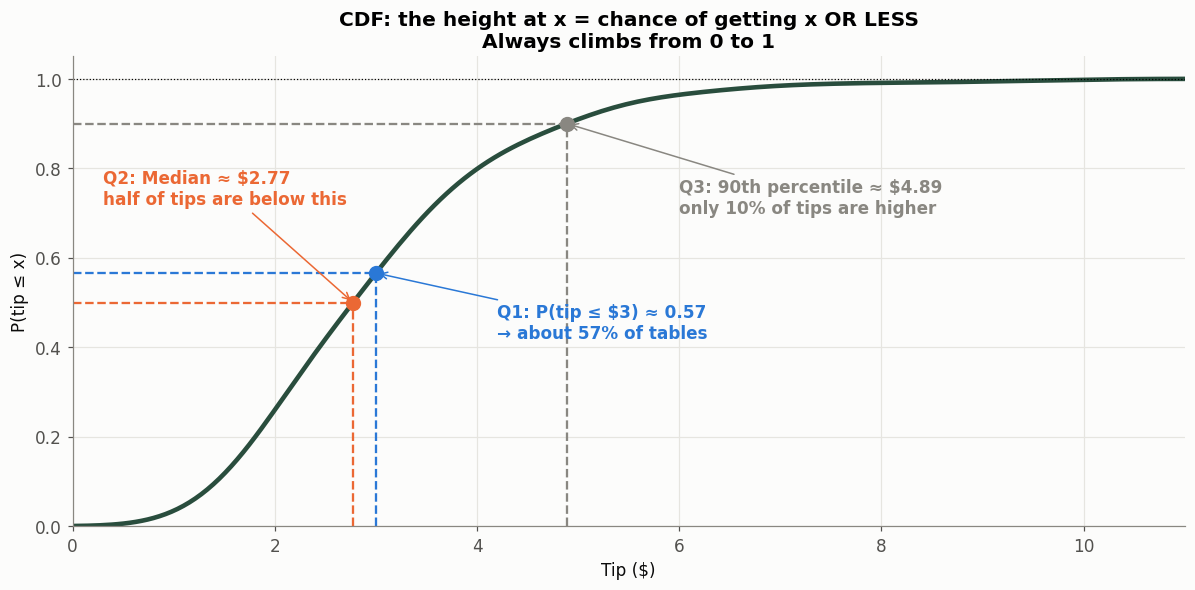

Check with the raw data:
  P(tip <= $3)     = 0.60
  Median tip       = $2.90
  90th percentile  = $5.00


In [26]:
fig, ax = plt.subplots(figsize=(11, 5.5))
sns.kdeplot(data=tips, x="tip", cumulative=True, color=GREEN, lw=3, ax=ax)
x, y = ax.lines[0].get_data()

def guide(xv, yv, color, text, text_xy):
    ax.plot([xv, xv], [0, yv], color=color, ls="--", lw=1.5)      # vertical guide
    ax.plot([0, xv], [yv, yv], color=color, ls="--", lw=1.5)      # horizontal guide
    ax.plot(xv, yv, "o", color=color, ms=9)
    ax.annotate(text, xy=(xv, yv), xytext=text_xy, fontsize=11, color=color,
                fontweight="bold", arrowprops=dict(arrowstyle="->", color=color))

# Q1: x to y. Chance of a tip of $3 or less
p3 = np.interp(3, x, y)
guide(3, p3, BLUE, f"Q1: P(tip ≤ $3) ≈ {p3:.2f}\n→ about {p3:.0%} of tables", (4.2, 0.42))

# Q2: y to x. Median (50th percentile)
med = np.interp(0.5, y, x)
guide(med, 0.5, ORANGE, f"Q2: Median ≈ ${med:.2f}\nhalf of tips are below this", (0.3, 0.72))

# Q3: y to x. 90th percentile
p90 = np.interp(0.9, y, x)
guide(p90, 0.9, GREY, f"Q3: 90th percentile ≈ ${p90:.2f}\nonly 10% of tips are higher", (6.0, 0.70))

ax.axhline(1, color="black", lw=0.8, ls=":")
ax.set(xlim=(0, 11), ylim=(0, 1.05), xlabel="Tip ($)", ylabel="P(tip ≤ x)")
ax.set_title("CDF: the height at x = chance of getting x OR LESS\nAlways climbs from 0 to 1",
             fontweight="bold")
plt.tight_layout(); plt.show()

print("Check with the raw data:")
print(f"  P(tip <= $3)     = {(tips.tip <= 3).mean():.2f}")
print(f"  Median tip       = ${tips.tip.median():.2f}")
print(f"  90th percentile  = ${tips.tip.quantile(0.9):.2f}")

> **Why do the curve and the raw data differ slightly?** The smooth CDF is built from the smoothed PDF, so it gives **estimates** (0.57, \$2.77, \$4.89). Counting the raw data gives 0.60, \$2.90 and \$5.00. Both tell the same story. For exact figures from the data, use the **ECDF** (Section 6).

### What the CDF captures
- **Running total.** The height at any point x is the **fraction of values ≤ x**.
- **Always goes up** (or stays flat). It never goes down, and it runs from **0** on the left to **1** on the right.
- **Steep parts** are where many values are packed (here \$2–\$4). **Flat parts** are where values are rare.
- **Percentiles** (median, 90th, etc.) can be read directly: go **up** to the level, then **across** to the curve, then **down**.
- **"More than" questions:** P(tip > x) = **1 − CDF(x)**

### How to describe it (sentence template)
> *"About **___%** of values are at or below **___**. The median is about **___**. The curve rises steeply between **___** and **___**, so most values lie there. Only **___%** exceed **___**."*

**Example answer:**
> About **60%** of tips are **\$3 or less**, and the **median** tip is just under **\$3**. The curve climbs steeply between **\$2 and \$4**, so most tips fall in that range. Only about **10%** of tables tip more than **~\$5**, so anything above \$5 is a great tip.

<details>
<summary><b>Quick check (click for answers)</b></summary>

1. What's the chance a tip is **more than** \$3? Answer: 1 − 0.60 ≈ **0.40**
2. Where on the curve are tips most common, the steep part or the flat part? Answer: The **steep** part.
3. Can a CDF ever go down? Answer: **No.** A running total can only grow or stay the same.
</details>


## 6. ECDF: Empirical CDF (Discrete: `size`)

### Problem statement
> **The manager is buying new tables.** She asks:
> *"If I only buy tables that seat up to **2**, what fraction of groups can I seat? What about tables up to **4**? What size should my biggest table be to seat at least **95%** of groups?"*
>
> **Task:** Draw the **ECDF** of `size` and answer all three questions from the steps.

**"Empirical"** means *"built directly from the data we observed"*. There's no smoothing: each step is real data.

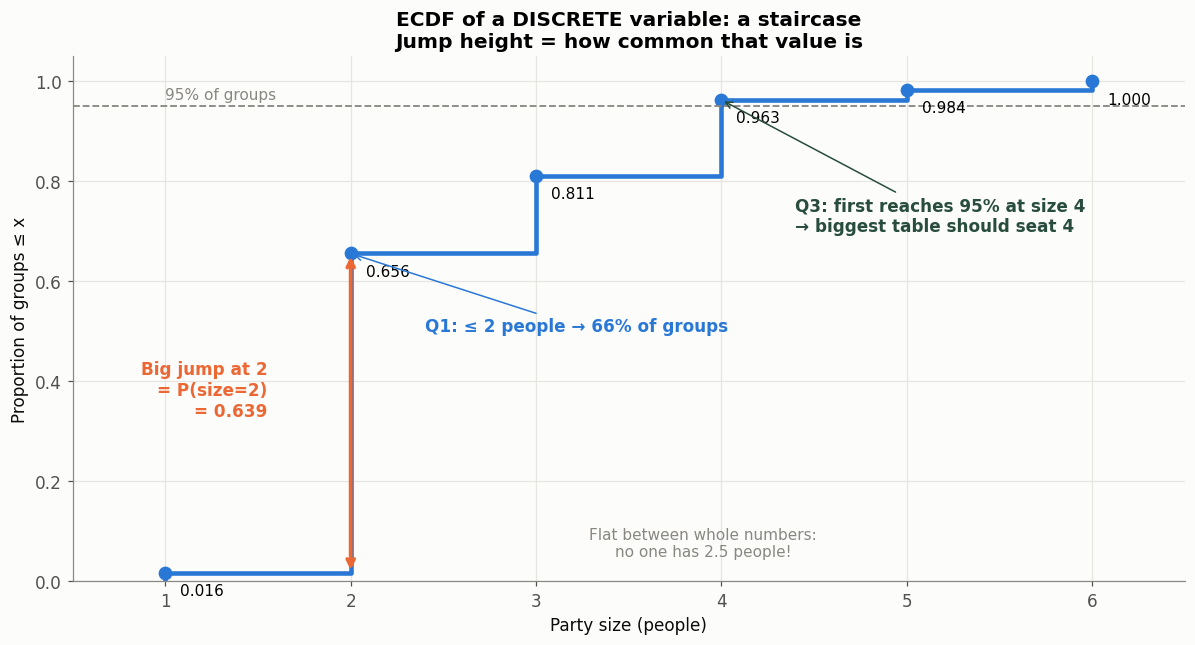

,PMF (jump size),ECDF (running total)
Party size,,
1,0.016,0.016
2,0.639,0.656
3,0.156,0.811
4,0.152,0.963
5,0.020,0.984
6,0.016,1.000


In [27]:
pmf  = tips["size"].value_counts(normalize=True).sort_index()
ecdf = pmf.cumsum()                                   # running total of the PMF

fig, ax = plt.subplots(figsize=(11, 6))
sns.ecdfplot(data=tips, x="size", color=BLUE, lw=3, ax=ax)

# Dot + label at the top of each step
for s, val in ecdf.items():
    ax.plot(s, val, "o", color=BLUE, ms=8)
    ax.text(s + 0.08, val - 0.045, f"{val:.3f}", fontsize=10)

# Show that each JUMP = the PMF bar for that value
ax.annotate("", xy=(2, ecdf[2]), xytext=(2, ecdf[1]),
            arrowprops=dict(arrowstyle="<->", color=ORANGE, lw=2.5))
ax.text(1.55, 0.33, f"Big jump at 2\n= P(size=2)\n= {pmf[2]:.3f}", color=ORANGE,
        fontsize=11, fontweight="bold", ha="right")

# Q3: the 95% line
ax.axhline(0.95, color=GREY, ls="--", lw=1.2)
ax.text(1.0, 0.965, "95% of groups", color=GREY, fontsize=10)
ax.annotate("Q3: first reaches 95% at size 4\n→ biggest table should seat 4",
            xy=(4, ecdf[4]), xytext=(4.4, 0.70), fontsize=11, color=GREEN, fontweight="bold",
            arrowprops=dict(arrowstyle="->", color=GREEN))

ax.annotate(f"Q1: ≤ 2 people → {ecdf[2]:.0%} of groups",
            xy=(2, ecdf[2]), xytext=(2.4, 0.50), fontsize=11, color=BLUE, fontweight="bold",
            arrowprops=dict(arrowstyle="->", color=BLUE))

ax.text(3.9, 0.05, "Flat between whole numbers:\nno one has 2.5 people!", fontsize=10, color=GREY, ha="center")

ax.set(xticks=range(1, 7), xlim=(0.5, 6.5), ylim=(0, 1.05),
       xlabel="Party size (people)", ylabel="Proportion of groups ≤ x")
ax.set_title("ECDF of a DISCRETE variable: a staircase\nJump height = how common that value is",
             fontweight="bold")
plt.tight_layout(); plt.show()

pd.DataFrame({"PMF (jump size)": pmf.round(3), "ECDF (running total)": ecdf.round(3)}).rename_axis("Party size")

<div style="background-color: maroon; color: white; padding: 10px; border-radius: 5px;">
    <h3> The Binomial Distribution </h3>
</div>

### The story
FreshMart is launching a new mango juice. A staff member hands out free samples. From past promotions, the store knows that **1 in 5 people (20%) who try a sample go on to buy the product.** Today, **20 shoppers** try it.

The marketing manager asks: *"What's the chance we sell to **8 or more** of them? If that happens, the promotion counts as a hit."*

### The idea
Many situations are just a **yes/no question asked repeatedly**:
- Does this shopper buy? *(yes/no)*
- Does this email get opened? *(yes/no)*
- Is this light bulb faulty? *(yes/no)*
- Is this café table a smoker? *(yes/no)*

A single yes/no trial is called a **Bernoulli trial**. Count the "yeses" over *n* repeated trials and that count follows a **binomial distribution**.

**When to use it, the BINS checklist:**
- **B**inary: each trial has only two outcomes (success/failure)
- **I**ndependent: one trial doesn't affect another
- **N**umber of trials is fixed in advance (n)
- **S**ame probability of success every time (p)


### Relevance and significance
The binomial is the basic model for **conversion rates, defect rates, survey results, clinical trials and A/B tests.** Every "X out of N said yes" figure you'll ever see is binomial underneath.

### Why a data scientist needs this
- **A/B testing:** 12 of 100 visitors clicked the new button and 9 of 100 clicked the old one. Is that a real improvement or luck? The binomial tells you.
- **Quality control:** if 3 of 50 parts are faulty, is the machine broken?
- **Classification:** logistic regression, one of the most widely used ML models, predicts *p* in a Bernoulli trial.



## Understanding *n* and *k* in the Binomial Formula

$$P(X = k) = \binom{n}{k} p^k (1-p)^{n-k}$$

The binomial formula answers one question: **"If I repeat something *n* times, what's the chance I get exactly *k* successes?"**



### *n* = the total number of trials

This is how many times you repeat the experiment, and it's fixed before you start. Each trial has only two outcomes, "yes" (success) or "no" (failure).

- Flipping a coin 10 times → $n = 10$
- Surveying 20 customers → $n = 20$

### *k* = the number of successes you're asking about

This is the specific count of "yeses" whose probability you want. It can be any whole number from $0$ to $n$.

- "What's the chance of exactly 3 heads?" → $k = 3$
- "What's the chance that exactly 15 customers are satisfied?" → $k = 15$

That leaves $n - k$ as the number of failures ("nos").



### Worked Example

You flip a fair coin 5 times. What's the chance of getting **exactly 2 heads**?

| Symbol | Meaning | Value |
|---|---|---|
| $n$ | number of flips | 5 |
| $k$ | number of heads | 2 |
| $n - k$ | number of tails | 3 |
| $p$ | chance of heads on one flip | 0.5 |

**Step 1: Probability of one particular order (e.g., HHTTT)**

$$p^k (1-p)^{n-k} = (0.5)^2 \times (0.5)^3 = \frac{1}{32}$$

**Step 2: Count how many different orders give 2 heads**

$$\binom{5}{2} = \frac{5!}{2!\,3!} = 10$$

(HHTTT, HTHTT, HTTHT, HTTTH, THHTT, THTHT, THTTH, TTHHT, TTHTH, TTTHH)

**Step 3: Multiply**

$$P(X = 2) = 10 \times \frac{1}{32} = 0.3125 \approx 31\%$$



**Easy way to remember:** *n* is how many times you try, and *k* is how many times you want it to work.



<div style="background-color: #4C294D; color: white; padding: 10px; border-radius: 5px;">
    <h3> A Sample problem using Binomial distribution  </h3>
</div>

# Binomial Distribution: The Pop Quiz Problem

## The Problem

A pop quiz has **5 multiple-choice questions**, each with **4 options** (A, B, C, D). You didn't study, so you guess every answer at random.

**What is the chance you get exactly 2 questions right?**



## Let us understand if this is a Binomial Problem

A problem is binomial when it passes **four checks**:

| Check | What it means | Does the quiz pass? |
|---|---|---|
| **1. Fixed number of tries** | You know in advance how many attempts there are |  Exactly 5 questions |
| **2. Only two outcomes per try** | Each attempt is a "success" or a "failure" |  Each answer is right or wrong |
| **3. Same chance of success every time** | The probability doesn't change from try to try |  Always 1 in 4 to guess right |
| **4. Tries are independent** | One result doesn't affect another |  Guessing Q1 right doesn't change your odds on Q2 |

The question also asks **how many successes** there are out of a fixed number of tries. That is exactly what the binomial formula answers.

> **Not binomial:**
> - "How many questions until you get your first right answer?" There is no fixed number of tries.
> - Drawing cards from a deck without putting them back. The chances change after each draw.

---

## The Formula

$$
P(X = k) = \binom{n}{k} \, p^k \, (1-p)^{n-k}
$$

| Symbol | Meaning | Our value |
|---|---|---|
| $n$ | Number of tries | 5 |
| $k$ | Number of successes we want | 2 |
| $p$ | Chance of success on one try | $\frac{1}{4}$ |
| $1-p$ | Chance of failure on one try | $\frac{3}{4}$ |
| $\binom{n}{k}$ | Number of different ways to arrange the successes | (calculated below) |

> **Tip for pen and paper:** use fractions, not decimals. The numbers stay clean.

---

## Step-by-Step Solution

### Step 1: Chance of one specific pattern

Pick one particular way to get exactly 2 right, say **right, right, wrong, wrong, wrong** (✓✓✗✗✗).

Because the questions are independent, multiply the chances:

$$
\frac{1}{4} \times \frac{1}{4} \times \frac{3}{4} \times \frac{3}{4} \times \frac{3}{4}
$$

Group them:

$$
\left(\frac{1}{4}\right)^2 \times \left(\frac{3}{4}\right)^3 = \frac{1}{16} \times \frac{27}{64} = \frac{27}{1024}
$$

This is the $p^k(1-p)^{n-k}$ part of the formula.

### Step 2: Count how many patterns there are

✓✓✗✗✗ isn't the only way to get 2 right. The 2 correct answers could be on **any** 2 of the 5 questions. Listing them:

```
1. ✓✓✗✗✗     6. ✗✓✗✓✗
2. ✓✗✓✗✗     7. ✗✓✗✗✓
3. ✓✗✗✓✗     8. ✗✗✓✓✗
4. ✓✗✗✗✓     9. ✗✗✓✗✓
5. ✗✓✓✗✗    10. ✗✗✗✓✓
```

There are **10 patterns**. Each has exactly two ✓ and three ✗, so each has the **same** chance, $\frac{27}{1024}$.

Listing gets tedious for bigger problems, so use the **"n choose k"** formula instead:

$$
\binom{n}{k} = \frac{n!}{k!\,(n-k)!}
$$

($5!$, read "5 factorial", means $5 \times 4 \times 3 \times 2 \times 1 = 120$.)

$$
\binom{5}{2} = \frac{5!}{2! \times 3!} = \frac{120}{2 \times 6} = \frac{120}{12} = 10
$$

This matches the list.

### Step 3: Multiply

10 patterns, each with chance $\frac{27}{1024}$:

$$
P(X = 2) = 10 \times \frac{27}{1024} = \frac{270}{1024}
$$

### Step 4: Turn it into a decimal and a percentage

$$
\frac{270}{1024} \approx 0.264 \approx 26.4\%
$$

> **Answer:** If you guess randomly, there's about a **26%** chance of getting exactly 2 out of 5 right.

---

## Bonus 1: The Full Picture

The same method works for every possible score. All the probabilities share the denominator 1024, so only the numerators need comparing:

| Correct answers ($k$) | $\binom{5}{k}$ | Numerator of $\left(\frac{1}{4}\right)^k \left(\frac{3}{4}\right)^{5-k}$ | Probability |
|---|---|---|---|
| 0 | 1 | 243 | 243/1024 ≈ 23.7% |
| 1 | 5 | 81 | 405/1024 ≈ 39.6% |
| 2 | 10 | 27 | 270/1024 ≈ 26.4% |
| 3 | 10 | 9 | 90/1024 ≈ 8.8% |
| 4 | 5 | 3 | 15/1024 ≈ 1.5% |
| 5 | 1 | 1 | 1/1024 ≈ 0.1% |
| **Total** | | | **1024/1024 = 100%**  |

- **Check:** All the probabilities add to exactly 1. This is a good way to catch arithmetic mistakes.
- Getting **1** right is the most likely outcome. That makes sense: on average, guessing gets you $5 \times \frac{1}{4} = 1.25$ right.

---

## Bonus 2: "At Least 1 Right"

"At least 1" means 1, 2, 3, 4 or 5, which is five calculations. The shortcut is to work out the **opposite** (0 right) and subtract it from 1:

$$
P(X \geq 1) = 1 - P(X = 0) = 1 - \left(\frac{3}{4}\right)^5 = 1 - \frac{243}{1024} = \frac{781}{1024} \approx 76.3\%
$$

---

## Summary of the Method

1. **Check** the four binomial conditions.
2. **Write down** $n$, $k$, $p$ and $1-p$.
3. **Find the chance of one pattern:** $p^k(1-p)^{n-k}$.
4. **Count the patterns:** $\binom{n}{k}$.
5. **Multiply** the two together.

<div style="background-color: #0f1056; color: white; padding: 10px; border-radius: 5px;">
    <h3> The normal distribution and the bell curve </h3>
</div>

### The story
In the 1870s, a scientist named **Francis Galton** built a board with rows of pins. Balls dropped from the top bounce left or right at each pin *at random*. You can't predict where any single ball will land. But after hundreds of balls, the pile at the bottom always forms the same shape: **a bell.**

### The idea
The **normal distribution** is a smooth, symmetric, bell-shaped curve. It's completely described by just two numbers:
- **μ (mean):** where the centre of the bell is
- **σ (standard deviation):** how wide the bell is

### Why does it show up so often in the real world?
1. Human and Animal Heights: Most adults cluster around an average height, with very short or very tall individuals becoming increasingly rare.
2. Birth Weights of Newborns: Infant birth weights form a classic bell curve, where the vast majority fall into a healthy middle range and extreme highs or lows are uncommon.
3. Leaf Sizes and Plant Characteristics: The length, surface area, or number of seeds on a specific plant species generally vary symmetrically around a standard mean.
4. Measurement and Observation Errors: Physical measurements of natural items, such as the diameter of raindrops, animal wingspans, or pebble sizes—naturally scatter around a true value due to minor random measurement variations.
5. physiological Traits: Resting heart rates, blood pressure levels in a healthy baseline population, and even intelligence quotient (IQ) scores closely mimic a normal curve.




### Symmetry and spread in machine learning
- **Standardisation:** most ML pipelines rescale features to mean 0 and SD 1 (`StandardScaler`) so that big-number features like salary don't swamp small-number ones like age.
- **Model assumptions:** linear regression assumes the prediction errors are normal and symmetric around 0.
- **Anomaly detection:** values far out in the tails of a bell curve get flagged as unusual (fraud, faulty sensors).

### Why a data scientist needs this
Confidence intervals, margins of error in polls ("±3%"), hypothesis tests and quality control limits are all built on the normal curve.

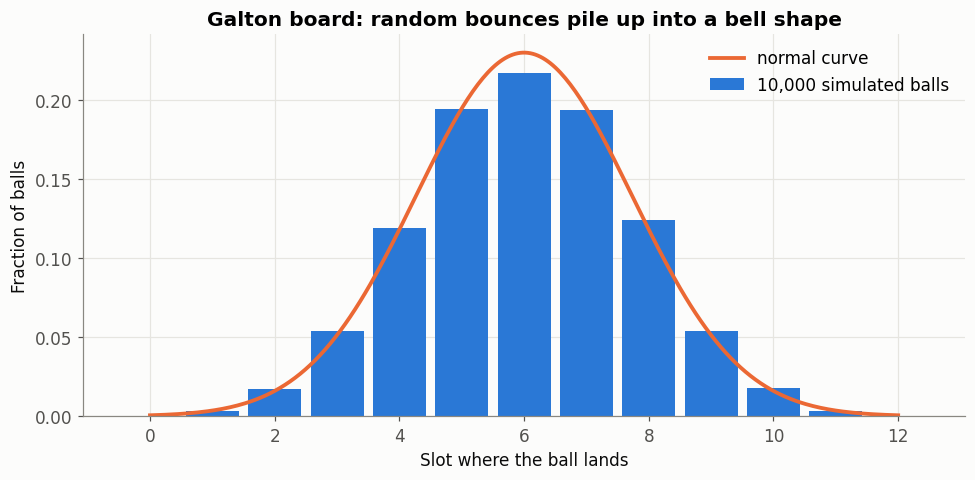

In [28]:
# Galton board simulation: 10,000 balls, 12 rows of pins, each bounce is left (0) or right (1)
balls, rows = 10_000, 12
slots = rng.integers(0, 2, size=(balls, rows)).sum(axis=1)   # final slot = number of 'rights'

counts = np.bincount(slots, minlength=rows + 1) / balls
x = np.arange(rows + 1)
mu, sigma = rows * 0.5, np.sqrt(rows * 0.25)
xs = np.linspace(0, rows, 300)

fig, ax = plt.subplots()
ax.bar(x, counts, color=BLUE, width=0.85, label="10,000 simulated balls")
ax.plot(xs, stats.norm.pdf(xs, mu, sigma), color=ORANGE, lw=2.5, label="normal curve")
ax.set_xlabel("Slot where the ball lands"); ax.set_ylabel("Fraction of balls")
ax.set_title("Galton board: random bounces pile up into a bell shape")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

<div style="background-color: maroon; color: white; padding: 10px; border-radius: 5px;">
    <h3> Properties of the Normal distribution  </h3>
</div>

## Symmetry, standard deviation, z-scores

### (a) Symmetry
The normal curve is a mirror image around its mean. That means:
- **mean = median = mode**, all at the centre,
- 50% of values are below the mean and 50% are above,
- the chance of being 5 above the mean is the same as the chance of being 5 below it.

### (b) Standard deviation: the "typical distance from the mean"
The **standard deviation (SD, σ)** measures **spread**, meaning how far values typically are from the mean.
- Small SD: values huddle close to the mean, giving a tall, narrow bell. The process is consistent.
- Large SD: values are spread out, giving a short, wide bell. The process is unpredictable.

**The 68–95–99.7 rule (the "empirical rule"):**
- about **68%** of values fall within **1 SD** of the mean,
- about **95%** fall within **2 SD**,
- about **99.7%** fall within **3 SD**. Anything beyond 3 SD is very rare.

### (c) Z-scores: "how many standard deviations from the mean?"
$$z = \frac{x - \mu}{\sigma}$$
- z = 0: exactly average
- z = +2: two SDs **above** average (better than about 97.7% of the group)
- z = −1: one SD **below** average

A z-score turns *any* normal distribution into the **standard normal** (mean 0, SD 1). That's what makes different things comparable.

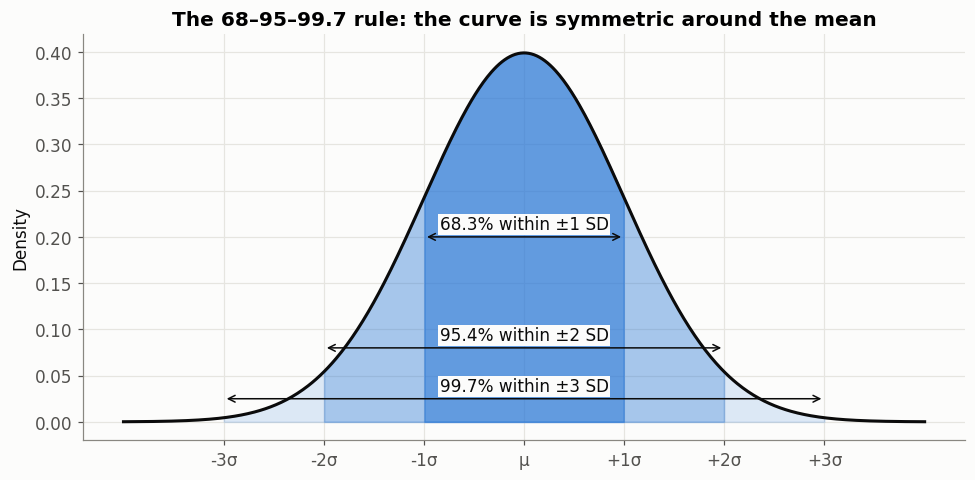

In [29]:
# The 68-95-99.7 rule, drawn on the standard normal
z = np.linspace(-4, 4, 600)
fig, ax = plt.subplots()
ax.plot(z, stats.norm.pdf(z), color=INK, lw=2)
for k_, c, a in [(3, BLUE, 0.15), (2, BLUE, 0.3), (1, BLUE, 0.55)]:
    m = (z >= -k_) & (z <= k_)
    ax.fill_between(z[m], stats.norm.pdf(z[m]), color=c, alpha=a)
for k_, y in [(1, 0.2), (2, 0.08), (3, 0.025)]:
    pct = (stats.norm.cdf(k_) - stats.norm.cdf(-k_)) * 100
    ax.annotate("", xy=(-k_, y), xytext=(k_, y), arrowprops=dict(arrowstyle="<->", color=INK))
    ax.text(0, y + 0.008, f"{pct:.1f}% within ±{k_} SD", ha="center", color=INK,
            bbox=dict(facecolor="#fcfcfb", edgecolor="none", pad=1))
ax.set_xticks(range(-3, 4)); ax.set_xticklabels(["-3σ", "-2σ", "-1σ", "μ", "+1σ", "+2σ", "+3σ"])
ax.set_ylabel("Density"); ax.set_title("The 68–95–99.7 rule: the curve is symmetric around the mean")
plt.tight_layout(); plt.show()

<div style="color:#004d99;"><h3> Variance </h3></div>

**Variance** measures how much the values **wobble around the mean**.

How to build it:
1. Find the mean.
2. For each value, find its **distance from the mean** (its *deviation*).
3. **Square** each distance. This makes every distance positive, and it makes big distances count much more.
4. Average the squares. For a sample we divide by $n - 1$ instead of $n$; this small correction gives a fairer estimate.

$$s^2 = \frac{\sum (x - \bar{x})^2}{n - 1}$$

**Small variance** → values huddle close to the mean (predictable). **Big variance** → values are scattered (unpredictable).

**One annoyance:** the units get squared (minutes² or £²!). That's why we usually take the square root → the **standard deviation** (next topic).

<div style="color:#004d99;"><h3> Calculate the variance with a pen and a paper </h3></div>

## Calculating Variance with Pen and Paper

**Numbers:** 12, 8, 10, 14, 9, 84, 10  (n = 7)

**Step 1: Find the mean**

$$
\bar{x} = \frac{12 + 8 + 10 + 14 + 9 + 84 + 10}{7} = \frac{147}{7} = 21
$$

**Step 2: Make a table of distances from the mean, and square them**

| Value $x$ | Distance from mean $(x - 21)$ | Squared distance |
|---|---|---|
| 12 | −9 | 81 |
| 8 | −13 | 169 |
| 10 | −11 | 121 |
| 14 | −7 | 49 |
| 9 | −12 | 144 |
| 84 | +63 | 3969 |
| 10 | −11 | 121 |
| | **Sum = 0** (always!) | **Sum = 4654** |

**Step 3: Divide the sum of squares by n − 1**

$$
s^2 = \frac{4654}{7 - 1} = \frac{4654}{6} = 775.67
$$



**Step 4 (optional): Standard deviation**

$$
s = \sqrt{775.67} \approx 27.85
$$

**What stands out:** the value 84 alone contributes 3,969 of the 4,654. Squaring makes far-away values **very** loud.

**Without the 84** (8, 9, 10, 10, 12, 14, mean 10.5): the squared distances are 6.25, 2.25, 0.25, 0.25, 2.25 and 12.25, which sum to 23.5, so $s^2 = 23.5 / 5 = 4.7$.

> One outlier takes the variance from **4.7 to 775.67**.

<div style="color:#004d99;"><h3> An example of why I would like to understand the variance of a given distribution </h3></div>



Application of Variance in data science and machine learning

1. **Comparing models**: Two models both average 90% accuracy across test runs. One scores 89–91% every time. The other jumps between 80% and 99%. You deploy the steady one.
2. **Business planning**: Two stores both average $10,000 in daily sales. The one with high variance needs extra stock and staff to handle unpredictable busy days.
3. **Investing**: Two stocks average the same return. The one with higher variance is riskier.
4. **Feature selection**: A feature with almost zero variance (e.g., every customer has the same value) can't help a model tell people apart, so it's usually dropped.

Summary: The average tells you what usually happens. The variance tells you how much you can rely on it.

<div style="background:	#001a33; color:#FFF; padding:15px; border-radius:5px;">

</div>

<div style="color:#004d99;"><h3> Standard Deviation </h3></div>

The **standard deviation** (SD, written $s$ or $\sigma$) is simply the **square root of the variance**:

$$s = \sqrt{\text{variance}}$$

Taking the square root brings the units back to minutes (or £), so it's easy to understand: *"waits are typically about s minutes away from the average."*

**The 68 – 95 – 99.7 rule** (for bell-shaped data):
- about **68 %** of values are within **1 SD** of the mean,
- about **95 %** within **2 SD**,
- about **99.7 %** within **3 SD**.

A value more than 3 SD from the mean is **very** unusual. The **z-score** $z = \dfrac{x - \text{mean}}{\text{SD}}$ tells you how many SDs away a value is.

<div style="color:#004d99;"><h3> Where is the standard deviation used ? </h3></div>

1. **Preparing data for AI (standardising):** turn every column into z-scores so that big numbers (like salary) don't overpower small ones (like age).
2. **Anomaly alarms:** flag values more than 3 SD from normal (e.g. an unusual heart rate on a smartwatch).
3. **Error bars** on charts and **margins of error** in opinion polls come from the SD.
4. **Manufacturing:** "Six Sigma" quality is named after the SD ($\sigma$).

<div style="color:#004d99;"><h3> Calculate the standard deviation with a pen and a paper </h3></div>

From B3: variance $= 775.67$ → $s = \sqrt{775.67} = \mathbf{£27.85}$

Without the $84: $s = \sqrt{4.7} = £2.17$.

**How unusual was the £84 shop?** Using a "normal hour" (mean £10.50, SD £2.17):

$$z = \frac{84 - 10.5}{2.17} = 33.9$$

Nearly **34 standard deviations** away: definitely not a typical top-up shop!



<div style="color:#004d99;"><h3> An example of why I would like to understand the standard deviation of a given distribution </h3></div>

## Why Calculate the Standard Deviation?

Variance tells you *how much* things vary, but it's measured in **squared units** ("minutes²"), which no one can picture. Standard deviation is the square root of variance, so it's back in the **original units** ("minutes"). That makes it a number you can use directly.

$$
\sigma = \sqrt{\text{Variance}}
$$

### Example: a pizza delivery promise

A pizza shop records its delivery times:

- **Average:** 30 minutes
- **Variance:** 25 minutes² (what does that even mean?)
- **Standard deviation:** $\sqrt{25}$ = **5 minutes**

Now the owner can reason in plain terms. For roughly bell-shaped data:

| Range | Share of deliveries |
|---|---|
| Average ± 1 SD: 25–35 min | about 68% |
| Average ± 2 SD: 20–40 min | about 95% |
| Average ± 3 SD: 15–45 min | about 99.7% |

So the owner can safely advertise **"Delivered in 40 minutes or it's free!"**, because only about 2–3% of orders will run past 40 minutes. The variance couldn't have told them that directly; the standard deviation does.

### Same idea in data science and machine learning

- **Feature scaling (standardization):** Age ranges from 20–60 and salary from 20,000–200,000. Without scaling, many models treat salary as more important just because its numbers are bigger. Rescaling each feature as $z = \frac{x - \mu}{\sigma}$ puts every feature on the same footing.
- **Outlier detection:** A transaction more than 3 SDs from a customer's usual spending gets flagged as possible fraud.
- **Reporting model results:** "Accuracy is 91% ± 1.5% across 5 cross-validation folds" shows whether the model is stable or just got lucky on one split.
- **Quality and monitoring:** If a server's response time is usually 200 ms ± 20 ms, an alert fires when it goes beyond 260 ms (3 SDs).

### Variance vs. standard deviation

| | Variance | Standard deviation |
|---|---|---|
| Units | Squared (min², \$²) | Same as the data (min, \$) |
| Easy to interpret? | No | Yes |
| Typically used for | Math and theory | Reporting, thresholds, scaling |

> **One-line summary:** Variance tells you that things are spread out. Standard deviation tells you **how far, in units you can use**.

<div style="background-color: #0f1056; color: white; padding: 10px; border-radius: 5px;">
    <h3>From probability to sampling: learning about everyone by looking at a few</h3>
</div>

### The story so far
Everything we've done so far used the waiter's notebook of **244 tables**. We counted, we computed probabilities, we drew distributions. But here's a question nobody has asked yet:

> *"Is the waiter's notebook the whole story, or just a slice of it?"*

The restaurant has served thousands of tables over the years. The waiter wrote down 244 of them, over a few months. So when we say "P(smoker) = 0.38", we really mean: **in this slice**, 38% of tables were smokers. Would a different slice say the same?

That's the big question for the rest of today: **how can we learn about everyone when we can only look at some of them?** People answer it every day, in every field:

| Where | What they wanted to know about **everyone** | What they actually looked at |
|---|---|---|
 **Vaccine trials** | Does the vaccine work for everyone? | The Pfizer COVID-19 trial tested about **43,000** volunteers. Its results guided decisions for billions of people. |

> **The soup analogy.** To check whether a big pot of soup needs salt, you don't drink the whole pot. You taste **one spoonful**. But you **stir first**. The pot is the **population**, the spoonful is the **sample**, and stirring is **random sampling**. Sections 1 to 4 are about those three things.

**Our flow of thought for the next four sections:**

| Step | The question | The idea |
|---|---|---|
| 1 | *Who* do we want to know about, and who can we actually look at? | **Population vs sample** |
| 2 | *How* should we pick who to look at? | **Sampling methods** |
| 3 | If we looked at a different group, *how much would our answer change?* | **Sampling distribution and standard error** |
| 4 | Why does that change always follow a bell curve? | **The Central Limit Theorem** |

<div style="background-color: #0f1056; color: white; padding: 10px; border-radius: 5px;">
    <h3>1. Population vs sample</h3>
</div>

### The story
The restaurant owner wants to set next month's prices. She asks one question:

> *"What's the average bill per table?"*

Every receipt the waiter handled is in the office: **all 244 of them**. But each one is a crumpled bit of paper, and she has a restaurant to run. She has time to read only **30 receipts**. Can 30 receipts tell her about all 244?

### The idea
- The **population** is **everyone (or everything) we want to know about**. Here: all 244 tables in the waiter's records.
- A **sample** is **the part we actually look at**. Here: the 30 receipts she reads.
- A number that describes the **population** is called a **parameter**. It's fixed, but usually *unknown*.
- A number that describes the **sample** is called a **statistic**. We can calculate it, but it *changes* from sample to sample.

We use the **statistic** to **estimate** the **parameter**.

| | **Population** | **Sample** |
|---|---|---|
| What it is | Everyone we care about | The part we actually measure |
| Size | **N** (here 244) | **n** (here 30) |
| Mean | **μ** ("mu"), a **parameter** | **x̄** ("x-bar"), a **statistic** |
| Standard deviation | **σ** ("sigma") | **s** |
| Proportion (e.g. share of smokers) | **p** | **p̂** ("p-hat") |
| Do we know it? | Almost never | Always, because we measured it |
| Does it change? | No, it's one fixed number | **Yes**: a different sample gives a different value |
| Cost to measure | High (time, money), sometimes impossible | Low |

**Memory trick:** **P**arameter goes with **P**opulation. **S**tatistic goes with **S**ample.

### Properties to remember
- **Population:** complete and fixed. Usually too big, too expensive or impossible to measure fully. Sometimes it doesn't even exist yet: "every table the restaurant will serve next year".
- **Sample:** a subset. Quick and cheap, **but it wobbles**: two different handfuls of 30 receipts give slightly different averages. That wobble is called **sampling variability** (Section 3).
- A **good sample is a mini-version of the population**, with the same mix of days, lunch and dinner, small and big tables. Whether that's true depends on *how* it was chosen (Section 2).

### "Population" depends on the question
The same data can be a population for one question and a sample for another:
- *"What was the average bill across the waiter's 244 tables?"* The 244 tables **are** the population. We can compute μ exactly.
- *"What's the average bill at this restaurant, ever?"* Then the 244 tables are just a **sample** of all the restaurant's tables, and 19.79 is an **estimate**.

So always ask first: **"What is the population I actually care about?"**

### Relevance and significance
Almost every number in the news is a **statistic reported as if it were a parameter**: "unemployment is 4.1%", "62% of teenagers use social media daily", "the average house price is £290,000". Someone measured a sample and reported it as if it described everyone.

### Practical applications
| Population (what we want to know about) | Sample (what we actually look at) |
|---|---|

| All of a supermarket's shoppers | The ones who answer a feedback survey |
| All the fish in a lake | The fish caught, measured and released |

### Why a data scientist needs this
**Every dataset you'll ever analyse is a sample**, even a huge one. Before drawing any conclusion, ask: *"What population is this a sample of, and does it fairly represent that population?"*

### Real-world problem

> **Problem.** The owner reads **30 randomly chosen receipts** out of the 244.
> 1. Estimate the average bill (x̄) and the share of smoking tables (p̂) from her 30 receipts.
> 2. This is a classroom, so we *can* also compute the true values for all 244 tables (μ and p). How close did 30 receipts get?

In [30]:
N = len(tips)            # population size
n_owner = 30             # sample size

# The owner's random sample of 30 receipts
owner_sample = tips.sample(n=n_owner, random_state=5)

In [31]:
# Sample Statistics: what the owner actually knows

# Sample Statistics: what the owner actually knows

x_bar = owner_sample["total_bill"].mean()
s     = owner_sample["total_bill"].std()               
p_hat = (owner_sample["smoker"] == "Yes").mean()


In [32]:
# Parameters: normally unknown, but here we can peek at all 244 tables

mu    = tips["total_bill"].mean()
sigma = tips["total_bill"].std()                 
p_pop = (tips["smoker"] == "Yes").mean()

In [33]:
# Comparing the Sample and the Population

print(f"{'':24}{'Sample (n=30)':>15}{'Population (N=244)':>21}")
print(f"{'Average bill ($)':24}{x_bar:>15.2f}{mu:>21.2f}")
print(f"{'Std deviation ($)':24}{s:>15.2f}{sigma:>21.2f}")
print(f"{'Share of smoker tables':24}{p_hat:>15.3f}{p_pop:>21.3f}")
print(f"\nReading just {n_owner/N:.0%} of the receipts, the owner's estimate "
      f"was off by ${abs(x_bar - mu):.2f}.")

                          Sample (n=30)   Population (N=244)
Average bill ($)                  19.29                19.79
Std deviation ($)                  8.70                 8.90
Share of smoker tables            0.400                0.381

Reading just 12% of the receipts, the owner's estimate was off by $0.50.


**A note on `std()`:** for a **sample**, pandas divides by **n − 1** (`ddof=1`, the default). For the **population** we tell it to divide by **N** (`ddof=0`). Dividing by n − 1 slightly corrects for the fact that a sample tends to *underestimate* the spread. You don't need to memorise this. Just know why the two are calculated slightly differently.

<div style="background-color: #0f1056; color: white; padding: 10px; border-radius: 5px;">
    <h3>2. Sampling methods: probability and non-probability</h3>
</div>

### The story
The owner is busy, so three people offer to pick the 30 receipts for her:

- **The manager** says: *"I only work weekend dinners, so I'll grab 30 receipts from my shifts. It's easy."*
- **The marketing assistant** says: *"Let's leave comment cards on the tables, and use the receipts of whoever fills one in."*
- **The data scientist** says: *"Number all 244 receipts. Let the computer pick 30 numbers completely at random. Read exactly those."*

All three will come back with an average. **Only one can be trusted.** Which one, and why?

### The idea
**How you choose the sample matters more than how big it is.** 

There are two families of sampling methods.

**Probability sampling:** every member of the population has a **known, non-zero chance** of being picked, and **chance, not a person, does the picking**.

| Method | How it works | Restaurant example | Good for |
|---|---|---|---|
| **Simple random** | Everyone has the same chance, like pulling names from a hat | Computer picks 30 of the 244 receipt numbers | The gold standard, when you have a full list |
| **Systematic** | Pick a random starting point, then every *k*-th one | Random start, then every 8th receipt in the book | Quick when working down a list, a queue or a production line |
| **Stratified** | Split into groups (**strata**) first, then pick randomly *inside every group*, in the right proportions | Random receipts from **each day** (Thur, Fri, Sat, Sun) in proportion to how busy each day is | Making sure every group is represented. Often a little more precise. |
| **Cluster** | Split into groups (**clusters**), pick a few *whole groups* at random, and look at everything in them | Pick 2 whole **shifts** at random and read every receipt from those shifts | Cheap when items come in natural bundles. But less precise if the groups differ. |

**Non-probability sampling:** people are picked because they're **easy to reach, volunteered, or were hand-picked by someone**. Some members have **no chance** of being chosen, so the sample can be unrepresentative in a consistent direction. This is called **bias**.

| Method | How it works | Restaurant example | The danger |
|---|---|---|---|
| **Convenience** | Whoever is easiest to reach | The manager's weekend-dinner receipts | Weekend dinners aren't typical of the whole week |
| **Voluntary response** | People choose themselves | Whoever fills in a comment card | Big groups have more people, so more chance someone fills one in |
| **Quota** | Fill a set number per group, but **choose freely** within it | "15 tables where a man paid, 15 where a woman paid", picked from the ones the waiter remembers | Right mix of groups, but people remember the big, expensive tables |
| **Judgement (purposive)** | An expert hand-picks "typical" cases | The waiter picks the receipts he thinks are "normal" | Only as good as the expert's guess |
| **Snowball** | Each person recruits the next | Regulars ask their friends to fill in a survey | Friends tend to be alike |

> **Stratified vs cluster** is the pair students mix up most. **Stratified:** take *some* from **every** group. **Cluster:** take *all* from **some** groups.

### Relevance and significance
- **Bias does not shrink when the sample gets bigger.** A biased method with 2.4 million people is still biased, just *confidently* wrong. A random sample of 1,000 beats it.
- Non-probability samples aren't useless. They're fine for early exploration, focus groups and pilot tests. You just can't use them to make precise claims about the whole population.

### Practical applications
- **Election polls:** stratified by region, age and gender, so every group is properly represented.
- **Factory quality checks:** systematic, testing every 100th item off the production line.
- **National health surveys:** cluster sampling. Pick random towns, then households within them, because visiting random homes across a whole country is too expensive.
- **Online reviews:** voluntary response. That's why reviews bunch up at 5 stars and 1 star: people with strong feelings are the ones who reply.

### Why a data scientist needs this
Most company data is **not** a random sample. It's app users, people who clicked, customers who complained. Knowing *how* data was collected tells you which population it really represents. A model trained on a biased sample makes biased predictions.

### Real-world problem: whose 30 receipts should the owner trust?

> **Problem.** Use each of the 7 methods below to pick about 30 of the 244 receipts, and estimate the average bill.
> One try could be lucky or unlucky, so **repeat each method 1,000 times** and see where its estimates land compared with the true μ.
>
> - A method whose estimates **centre on μ** is **unbiased**.
> - A method whose estimates are **tightly bunched** is **precise**.
> - We want both.

First we need one extra column. The receipts are in the order they were written, so every time the day or the lunch/dinner time changes, a new **shift** begins. Shifts are our **clusters**.

In [34]:
day_time = tips["day"].astype(str) + " " + tips["time"].astype(str)
tips["shift"] = (day_time != day_time.shift()).cumsum()        # 1, 2, 3, ... each time the shift changes
print(f"The 244 receipts come from {tips['shift'].nunique()} shifts.")
tips.groupby("shift").agg(day=("day", "first"), time=("time", "first"), tables=("total_bill", "size")).T

The 244 receipts come from 17 shifts.


shift,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
day,Sun,Sat,Sun,Sat,Thur,Fri,Sat,Sun,Thur,Sun,Sat,Sun,Thur,Sat,Fri,Sat,Thur
time,Dinner,Dinner,Dinner,Dinner,Lunch,Dinner,Dinner,Dinner,Lunch,Dinner,Dinner,Dinner,Lunch,Dinner,Lunch,Dinner,Dinner
tables,19,22,15,21,13,12,10,5,33,18,4,19,15,14,7,16,1


In [35]:
n_pick = 30
day_share = tips["day"].value_counts(normalize=True)

# ---------- probability methods ----------
def simple_random():
    return tips.sample(n_pick, random_state=rng.integers(1e9))

def systematic():
    k = len(tips) // n_pick                     # every k-th receipt (k = 8)
    start = rng.integers(k)                     # random starting point
    return tips.iloc[start::k].head(n_pick)

def stratified():
    # random receipts from EVERY day, in proportion to how busy each day is
    parts = [tips[tips["day"] == d].sample(round(share * n_pick), random_state=rng.integers(1e9))
             for d, share in day_share.items()]
    return pd.concat(parts)

def cluster():
    # pick 2 WHOLE shifts at random and read every receipt from them
    chosen = rng.choice(tips["shift"].unique(), size=2, replace=False)
    return tips[tips["shift"].isin(chosen)]

# ---------- non-probability methods ----------
def convenience():
    # the manager: only the weekend dinners he works
    weekend = tips[tips["day"].isin(["Sat", "Sun"])]
    return weekend.sample(n_pick, random_state=rng.integers(1e9))

def voluntary():
    # comment cards: each diner might fill one in, so bigger groups are more likely to reply
    return tips.sample(n_pick, weights=tips["size"], random_state=rng.integers(1e9))

def quota():
    # 15 tables where a man paid, 15 where a woman paid, but chosen from the ones the waiter
    # remembers: bigger bills are more memorable
    parts = [tips[tips["sex"] == g].sample(n_pick // 2, weights=tips.loc[tips["sex"] == g, "total_bill"],
                                           random_state=rng.integers(1e9))
             for g in ["Male", "Female"]]
    return pd.concat(parts)

methods = {"Simple random": simple_random, "Systematic": systematic, "Stratified": stratified,
           "Cluster (2 shifts)": cluster, "Convenience": convenience,
           "Voluntary response": voluntary, "Quota": quota}
probability_methods = ["Simple random", "Systematic", "Stratified", "Cluster (2 shifts)"]

In [36]:
# One try with each method
print(f"True average bill μ = ${mu:.2f}\n")
print(f"{'Method':20}{'Family':>17}{'tables':>8}{'x̄ ($)':>9}{'Error ($)':>11}")
for name, pick in methods.items():
    chosen = pick()
    family = "probability" if name in probability_methods else "non-probability"
    print(f"{name:20}{family:>17}{len(chosen):>8}{chosen['total_bill'].mean():>9.2f}"
          f"{chosen['total_bill'].mean() - mu:>+11.2f}")

True average bill μ = $19.79

Method                         Family  tables   x̄ ($)  Error ($)
Simple random             probability      30    19.43      -0.35
Systematic                probability      30    19.93      +0.15
Stratified                probability      30    20.08      +0.29
Cluster (2 shifts)        probability      23    22.41      +2.62
Convenience           non-probability      30    19.62      -0.17
Voluntary response    non-probability      30    21.46      +1.67
Quota                 non-probability      30    23.01      +3.23


In [37]:
# Repeat every method 1,000 times: where do its estimates land?
REPEATS = 1_000
results = {name: np.array([pick()["total_bill"].mean() for _ in range(REPEATS)])
           for name, pick in methods.items()}

summary = pd.DataFrame({
    "average estimate ($)": {k: v.mean() for k, v in results.items()},
    "bias ($)":             {k: v.mean() - mu for k, v in results.items()},
    "spread ($)":           {k: v.std() for k, v in results.items()},
}).round(2)
summary

,average estimate ($),bias ($),spread ($)
Simple random,19.78,-0.00,1.48
Systematic,19.79,0.01,1.68
Stratified,19.72,-0.07,1.48
Cluster (2 shifts),20.12,0.33,2.10
Convenience,20.92,1.13,1.54
Voluntary response,21.56,1.78,1.61
Quota,22.89,3.10,1.52


<div style="background-color: #4C294D; color: white; padding: 10px; border-radius: 5px;">
    <h3> Visualizing the distribution  </h3>
</div>

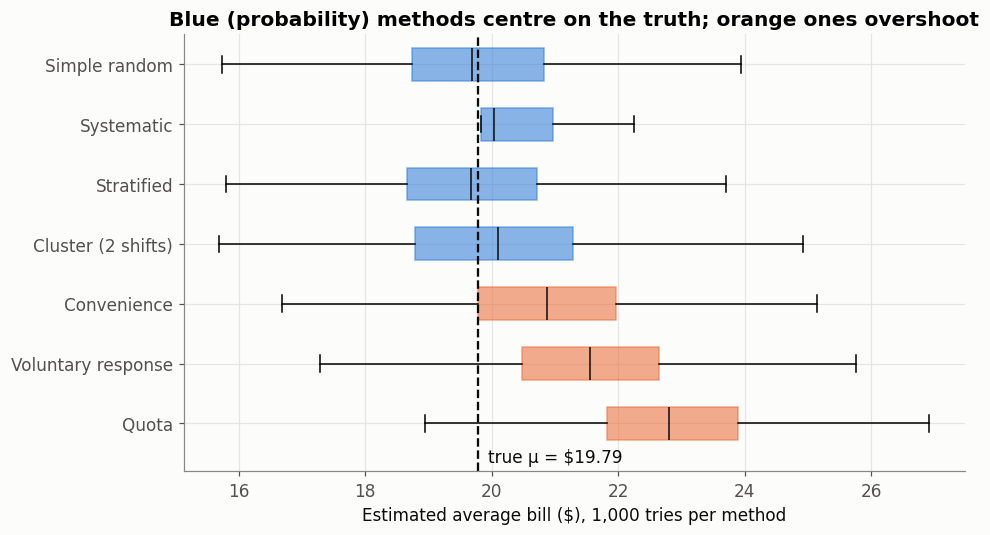

In [38]:
names  = list(results)[::-1]                 # keep the table's order, top to bottom
colors = [BLUE if m in probability_methods else ORANGE for m in names]

fig, ax = plt.subplots(figsize=(9, 5))
bp = ax.boxplot([results[m] for m in names], vert=False, widths=0.55, patch_artist=True,
                showfliers=False, medianprops=dict(color=INK))
for patch, c in zip(bp["boxes"], colors):
    patch.set_facecolor(c); patch.set_alpha(0.55); patch.set_edgecolor(c)
ax.set_yticks(range(1, len(names) + 1)); ax.set_yticklabels(names)
ax.axvline(mu, color=INK, ls="--", lw=1.5)
ax.text(mu + 0.15, 0.35, f"true μ = ${mu:.2f}", color=INK)
ax.set_ylim(0.2, len(names) + 0.5)
ax.set_xlabel("Estimated average bill ($), 1,000 tries per method")
ax.set_title("Blue (probability) methods centre on the truth; orange ones overshoot")
plt.tight_layout(); plt.show()

**Things to note:**
- **Simple random, systematic and stratified** all centre on the true μ: they're **unbiased**, with similar spread. Stratifying by day helps only a little here, because bills vary much more *within* a day than *between* days.
- **Cluster** is also centred on μ, but it's the **widest**. Two shifts might be two quiet Thursday lunches or two busy Saturday dinners, so the estimate swings a lot. Cluster sampling is cheap, but imprecise.
- **Convenience, voluntary response and quota** are all **shifted to the right**. Any single try might land near μ by luck, but **on average** they overestimate the bill, and repeating them just repeats the same mistake. Quota is the worst here, at about \$3 too high. This is exactly what went wrong for the *Literary Digest*.
- **Quota** gets the male/female mix exactly right and *still* overshoots, because *within* each group it favours memorable, expensive tables.

**Bias vs noise, the dartboard picture:**
- **Noise (random error):** darts scattered *around* the bullseye. A bigger sample reduces it.
- **Bias:** darts bunched together in the *wrong place*. A bigger sample does **not** fix it. Only a better method does.

**Application:** before trusting any survey or dataset, ask one question: **"How were these chosen?"** If the answer is "whoever replied" or "whoever was easy to reach", be suspicious, however big the sample is.

<div style="background-color: #0f1056; color: white; padding: 10px; border-radius: 5px;">
    <h3>3. Sampling distribution of the mean and standard error</h3>
</div>

## Standard Error

**Standard error tells you how much your average would change if you took a different sample.** In other words, it measures how much you can trust your average.

### A simple example

You want to know the average height of adults in your city. You can't measure everyone, so you measure 50 random people and get **5 ft 7 in**.

If a friend measured a *different* 50 people, they might get 5 ft 6.5 in, and another friend might get 5 ft 7.5 in. Each sample gives a slightly different average.

**The standard error is the typical amount these averages differ from each other**, and from the true city-wide average.

- **Small standard error:** everyone's averages land close together, so your number is reliable.
- **Large standard error:** the averages bounce around a lot, so your number is shaky.

### Standard deviation vs. standard error

People often confuse these two.

| | What it measures | Height example |
|---|---|---|
| **Standard deviation** | How much **individual people** differ from each other | People range from 5 ft to 6 ft 4 in, so the spread is large |
| **Standard error** | How much **the average** would differ between samples | The average of 50 people barely moves, so the spread is small |

Individuals vary a lot, but averages of groups vary much less, because tall and short people cancel each other out.

### What makes it smaller?

$$
\text{Standard Error} = \frac{\sigma}{\sqrt{n}}
$$

where $\sigma$ is the standard deviation and $n$ is the sample size.

- **More data gives a smaller standard error.** Measuring 500 people instead of 50 makes your average much more trustworthy.
- But it grows slowly: to **halve** the standard error, you need **four times** as much data.

### Where you see it in real life

- **Election polls:** "52% ± 3%". That ± is based on the standard error.
- **Model accuracy:** "92% ± 2.4%". It tells you whether one model is truly better than another or just got lucky.
- **A/B tests:** It tells you whether a difference between two versions is real or just random noise.


<div style="background-color: #4C294D; color: white; padding: 10px; border-radius: 5px;">
    <h3> Simple problem for sampling distribution of mean and standard error  </h3>
</div>

## Part 1: Explained in an easy way

### The problem these ideas solve

Suppose you want the **average height of all adults in your city**. You can't measure millions of people, so you measure a **sample** of 25 and take their average.

Your sample average won't exactly match the true city average, because you happened to pick a few tall or short people. **How far off might your answer be?** These two ideas answer that question.

### Sampling distribution of the mean

Imagine **many people** each doing the same survey separately, each measuring a different random group of 25 adults:

| Researcher | Their sample average |
|---|---|
| 1 | 169.8 cm |
| 2 | 171.5 cm |
| 3 | 168.9 cm |
| 4 | 170.4 cm |
| … | … |
| 1,000 | 170.9 cm |

Every researcher gets a slightly different answer. If you collected all 1,000 averages and plotted them, you'd see a pile of numbers bunched around the true average.

> **That pile of sample averages is the sampling distribution of the mean.** It shows all the different answers you *could* have got, just from the luck of which people ended up in your sample.

Three things are true about this pile:

1. **It's centred on the true average.** Sampling doesn't lean too high or too low on average. The errors balance out.
2. **It's much narrower than the spread of individual heights.** One person can be 150 cm or 195 cm, but an average of 25 people rarely lands that far out. The tall and short people within each sample cancel each other out.
3. **It has a bell shape**, even when the individual data doesn't. This is called the **Central Limit Theorem** (below).

In practice, you only do the survey **once**. The pile of averages is imaginary, but it tells you how much to trust your one result.

### Standard error

> **The standard error is the standard deviation of that pile of sample averages.** In plain words, it's the typical amount by which a sample average misses the true average.

There's a simple formula for it:

$$
\text{Standard Error} = \frac{\sigma}{\sqrt{n}} = \frac{\text{Standard deviation of individuals}}{\sqrt{\text{sample size}}}
$$

**Example:** suppose individual heights in the city have a standard deviation of **10 cm**.

| Sample size | Calculation | Standard error | What it means |
|---|---|---|---|
| 25 people | 10 ÷ √25 = 10 ÷ 5 | **2 cm** | Your average is typically within about 2 cm of the truth |
| 100 people | 10 ÷ √100 = 10 ÷ 10 | **1 cm** | Within about 1 cm |
| 400 people | 10 ÷ √400 = 10 ÷ 20 | **0.5 cm** | Within about 0.5 cm |

**Bigger samples give more precise averages.** But because of the square root, you need **4 times** the people to make the error **half** as big.

### Standard deviation vs standard error

| | Standard deviation | Standard error |
|---|---|---|
| **Measures the spread of…** | Individual values | Sample averages |
| **Answers the question** | "How different are people from each other?" | "How far off is my average likely to be?" |
| **Gets smaller with a bigger sample?** | No, people don't become more alike | Yes |
| **Height example** | 10 cm | 2 cm (with 25 people) |

### Where you see it

- **Opinion polls:** "52% support, **margin of error ±3%**." That margin is about 2 standard errors.
- **Confidence intervals:** "We're 95% confident the true average is between 166 and 174 cm" means sample average ± about 2 standard errors.
- **Medical trials and A/B tests:** the standard error is used to judge whether a difference between two groups is real or just sampling luck.
- **Error bars** on charts often show the standard error.

---


<div style="background-color: #0f1056; color: white; padding: 10px; border-radius: 5px;">
    <h3>4. The Central Limit Theorem</h3>
</div>

# Central Limit Theorem (CLT)

When we want to study a large population, measuring every member is usually impractical. Instead, we draw **samples** from the population and use them to draw conclusions about it.

The **Central Limit Theorem** states that:

> The mean of samples (size ≥ 30) follows a **normal distribution**, no matter what the distribution of the underlying population is.

### Key properties
- The mean of the sampling distribution is approximately equal to the **population mean** (μ).
- The spread of the sample means (standard error) is **σ / √n**, so it shrinks as the sample size *n* grows.
- Larger samples capture more of the population's diversity, so the sample mean becomes a more accurate estimate.

## Step 1: Create a non-normal population

To show that the CLT works regardless of the population's shape, we generate a population from an **exponential distribution**, which is strongly right-skewed and clearly *not* normal.

Population mean: 0.9942
Population std : 0.9950


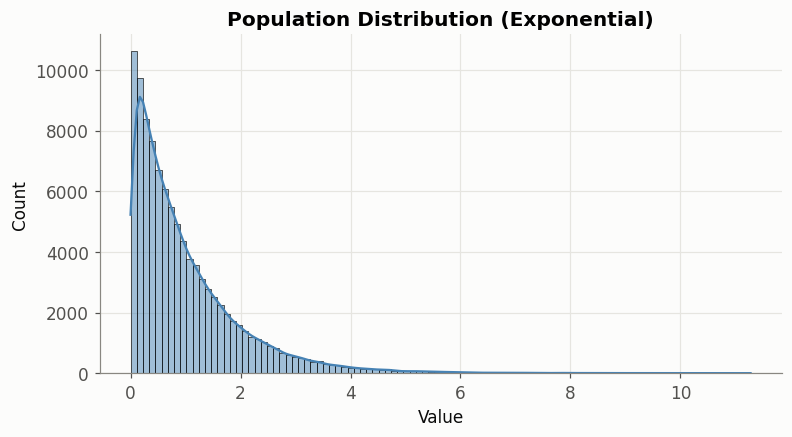

In [39]:
# create an exponential distribution with mean 1 and standard deviation 1; with population size 100,000

population = np.random.exponential(scale=1.0, size=100000)

print(f"Population mean: {population.mean():.4f}")
print(f"Population std : {population.std():.4f}")

plt.figure(figsize=(8, 4))
sns.histplot(population, bins=100, kde=True, color="steelblue")
plt.title("Population Distribution (Exponential)")
plt.xlabel("Value")
plt.show()

## Step 2: Draw many samples and compute their means

We take **1,000 random samples**, each of **size 30**, and record the mean of each sample. The resulting collection of means is called the **sampling distribution of the mean**.

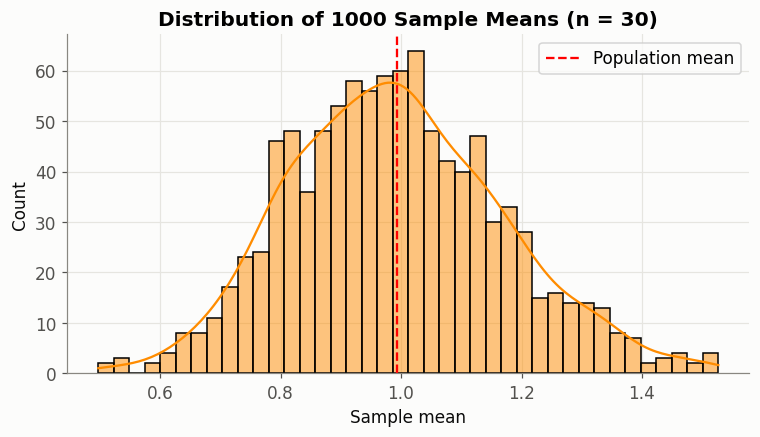

In [40]:
n_samples = 1000
sample_size = 30


#
sample_means = [
    np.random.choice(population, size=sample_size, replace=True).mean()
    for i in range(n_samples)
]

plt.figure(figsize=(8, 4))
sns.histplot(sample_means, bins=40, kde=True, color="darkorange")
plt.axvline(population.mean(), color="red", linestyle="--", label="Population mean")
plt.title(f"Distribution of {n_samples} Sample Means (n = {sample_size})")
plt.xlabel("Sample mean")
plt.legend()
plt.show()

In [41]:
mu = population.mean()
sigma = population.std()

print(f"Mean of sample means      : {np.mean(sample_means):.4f}  (population mean = {mu:.4f})")
print(f"Std of sample means       : {np.std(sample_means):.4f}")
print(f"Theoretical std error σ/√n: {sigma / np.sqrt(sample_size):.4f}")

Mean of sample means      : 0.9916  (population mean = 0.9942)
Std of sample means       : 0.1766
Theoretical std error σ/√n: 0.1817


## Step 4: Effect of sample size, on why 30 matters

Next we repeat the experiment with different sample sizes. With **small samples** (e.g., 2 or 5), the distribution of means still looks skewed like the population. Around **n = 30 and above**, it closely resembles a **normal distribution** and gets narrower as *n* increases.

This makes n ≈ 30 a practical rule-of-thumb threshold for applying the CLT.

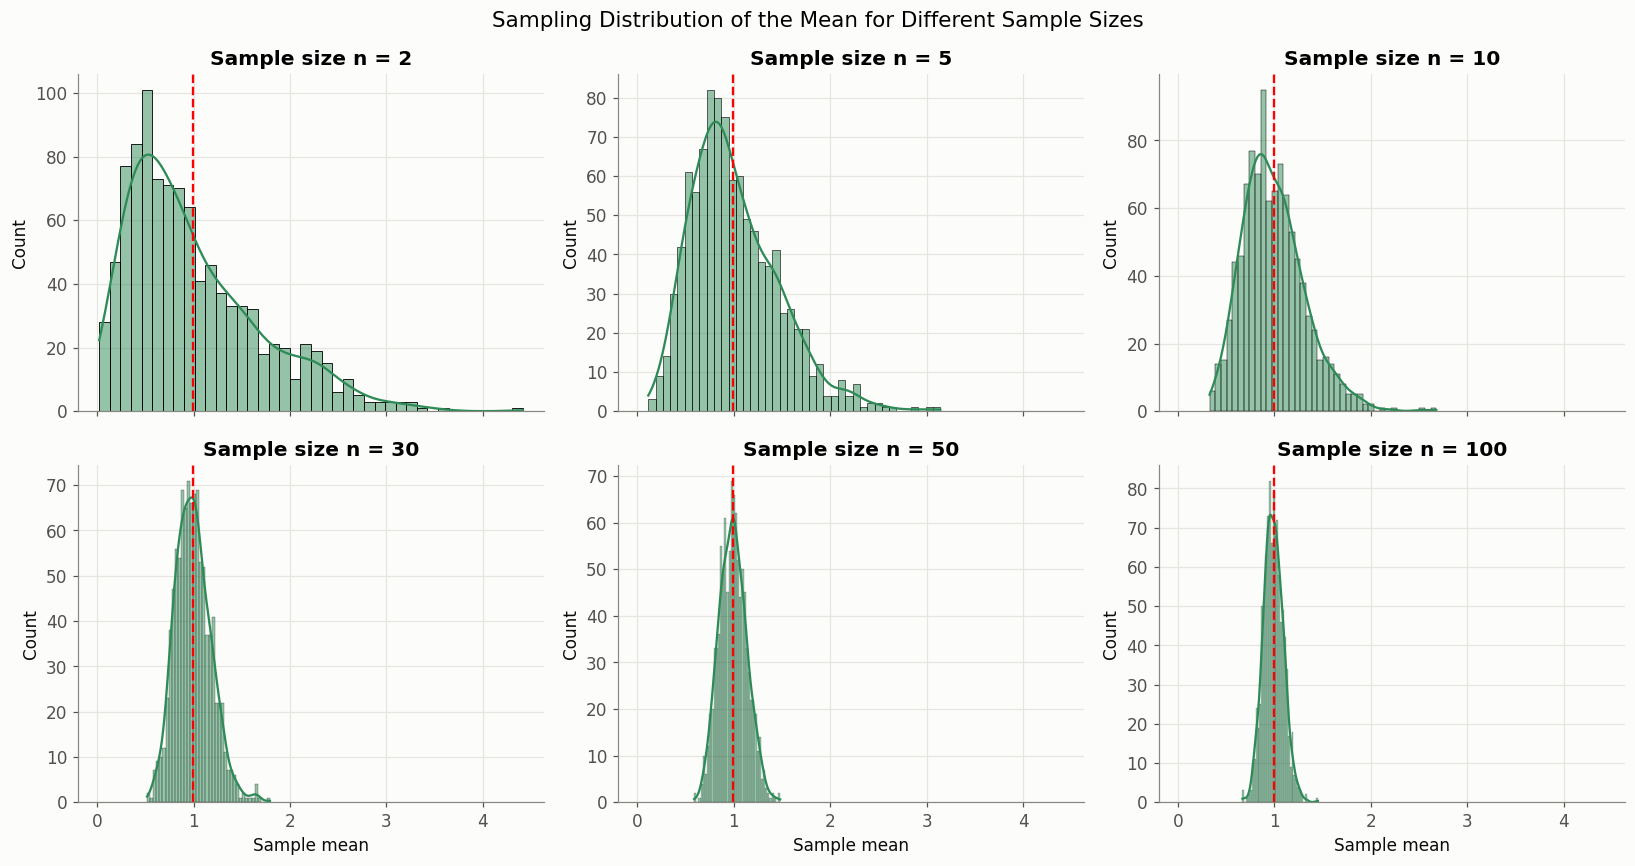

In [42]:
sample_sizes = [2, 5, 10, 30, 50, 100]

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)

for ax, n in zip(axes.flat, sample_sizes):
    means = [np.random.choice(population, size=n).mean() for _ in range(n_samples)]
    sns.histplot(means, bins=40, kde=True, ax=ax, color="seagreen")
    ax.axvline(mu, color="red", linestyle="--")
    ax.set_title(f"Sample size n = {n}")
    ax.set_xlabel("Sample mean")

plt.suptitle("Sampling Distribution of the Mean for Different Sample Sizes", fontsize=14)
plt.tight_layout()
plt.show()

## Conclusion

- Even though the population is **exponential (skewed)**, the means of samples of size ≥ 30 are approximately **normally distributed**.
- The mean of the sample means is very close to the **population mean**.
- As the sample size increases, the sampling distribution becomes **narrower** (smaller standard error), so estimates become more accurate.
- This is why the CLT is fundamental to confidence intervals, hypothesis testing, and A/B testing in data science.

<div style="background-color: #0f1056; color: white; padding: 10px; border-radius: 5px;">
    <h3>Putting it all together</h3>
</div>

| Idea | One-line meaning | In our restaurant |
|---|---|---|
| **Population** | Everyone we want to know about. Its numbers (**parameters**: μ, σ, p) are fixed but usually unknown. | All 244 tables in the waiter's records |
| **Sample** | The part we actually measure. Its numbers (**statistics**: x̄, s, p̂) are known but wobble. | The owner's 30 receipts |
| **Sampling method** | *How* the sample is chosen. Random methods are unbiased; convenience and volunteer samples usually aren't. | Computer-picked receipts vs "my weekend shifts" |
| **Sampling distribution** | The pattern of x̄ from many repeated samples. | 10,000 simulated nights |
| **Standard error** | How much x̄ typically wobbles: **σ/√n**. Shrinks as samples get bigger, but slowly. | About \$1.60 for 30 tables |
| **Central Limit Theorem** | For large enough n, x̄ (and totals) are approximately normal, whatever the population's shape. | Skewed tips → bell-shaped nightly totals → a predictable Saturday |

**The flow of thought:**
we want a fact about the **population** → we can only afford a **sample** → we must pick it **randomly**, or it's biased → even a random sample **wobbles**, by one **standard error** → thanks to the **CLT**, that wobble follows a **bell curve** → so we can say *how sure* we are. (Next session: **confidence intervals** and **hypothesis tests**.)
